# Lab 07 – Evaluating Unsupervised Models: When Metrics Disagree

**Data Science Lab 83-554 · Bar-Ilan University · Dr. Alexandra Litinsky Simanovsky**

In the previous lab you chose a clustering and defended it. Today the question is the one behind that choice: **how do you decide that an unsupervised model is good, when different metrics, assumptions and goals disagree?**

**The story.** A field-biology team recorded frog calls in 59 recording sessions. Each session recorded **one calling frog**, with whatever microphone and placement the team had that night. Besides the calls, every session kept a few short **background segments** – the same microphone, no frog calling. The team wants to sort new recordings by species without listening to every one, and asks you which clustering to trust. You will first decide how to normalize the recordings, then compare internal metrics, stability, information criteria and three algorithms, and only then open a taxonomy the biologists kept hidden from you. Finally you will see how a score can improve for the wrong reason, test on sessions the model has never heard, and write them a recommendation.

The goal is not to discover one magic score. A clustering has no single "accuracy", and by the end you will be able to say what each number does and does not tell you.

| Block | Topic | Exercises | Time |
|---|---|---|---|
| 0 | Audit and a first look | 1–2 | ~15 min |
| 1 | Normalize by what? Microphones and recordings | 3–6 | ~35 min |
| 2 | Internal evaluation: K-Means | 7–9 | ~25 min |
| 3 | Stability: does the answer survive re-running? | 10–11 | ~15 min |
| 4 | Other algorithms: GMM, Ward and DBSCAN | 12–15 | ~35 min |
| 5 | Reveal the taxonomy: external evaluation | 16–21 | ~45 min |
| 6 | Leakage and new recording sessions | 22–24 | ~25 min |
| 7 | Find the bug | 25–27 | ~15 min |
| 8 | Integrated challenge: the evaluation report | 28 | ~20 min |
| 9 | Working with an LLM, critically | 29–30 | ~15 min |
| 10 | Further investigations ★ (extra) | 31–33 |  |

Plan: about 245 minutes.

**★ = extra.** Exercises marked ★ (all of Block 10) are extra practice: do them if you finish early. Whatever you do not finish in class, you finish on your own.

**How to work**
- Each exercise shows the **expected output** (a chart, a table, or a description of the result) under an empty cell. Write code that produces it, then run the cell – your output replaces the expected one, so save your own copy and keep the original open.
- Hints are collapsed under each exercise. Try first, open them only if you are stuck.
- Where an exercise says *explain*, write your answer in a short comment or a Markdown cell, in English or Hebrew. A number from your own output is part of a good answer.
- Exercises depend on each other and run **in order, once**: if a result looks strange, restart from the first cell instead of re-running a single cell.
- The first code cell is supplied: imports, `RANDOM_STATE`, `TSNE_ITER` and two helpers – `share_between` measures how much of the variance lies between groups, and `plot_sessions` draws a 2D map with the largest sessions in colour.
- Unless an exercise says otherwise, fit K-Means with `n_init=20, random_state=RANDOM_STATE`, so that your numbers match the expected ones.
- **Don't read ahead.** Make your choices in Blocks 1–4 before you look at the taxonomy, or the comparison in Block 5 means nothing.
- Cluster numbers are arbitrary, so compare groups and not their numbers. Expected outputs were produced with pandas 2.2 and scikit-learn 1.4. On other versions, some numbers can differ slightly – that is fine.
- Submit in pairs: the notebook and an identical PDF, with both names and IDs in the Markdown cell below this one.

**Data** (folder `data/`, next to this notebook)
- `frog_calls.csv` – call syllables: `sample_id`, `recording_session` and 22 acoustic coefficients `mfcc_01, …, mfcc_22` (MFCCs: a compact description of the sound's spectrum). `sample_id` and `recording_session` are metadata, not acoustic measurements.
- `session_background.csv` – 3–5 background segments per session: `recording_session`, `segment` and the same 22 coefficients, measured through the same microphone while no frog was calling.
- `frog_taxonomy_reveal.csv` – the biologists' reference taxonomy (family, genus, species, in coded names) for every `sample_id`. Open it **only from Block 5 on**.

Source: adapted from the UCI [Anuran Calls (MFCCs)](https://doi.org/10.24432/C5CC9H) dataset (J. Colonna, E. Nakamura, M. Cristo and M. Gordo, CC BY 4.0). The course staff took 6,000 of its syllables and changed them: a small jitter, a different simulated microphone per recording, simulated background segments, new session numbers and IDs, coded taxonomy names, and an export error.

**Student 1 (name + ID):** Amir Golan 216264333

**Student 2 (name + ID):** Idan Persky 215548512

In [1]:
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from scipy.stats import entropy

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score, rand_score, mutual_info_score, classification_report
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from threadpoolctl import threadpool_limits

threadpool_limits(2)  # keeps K-Means quick and avoids a memory-leak warning on Windows
RANDOM_STATE = 42
TSNE_ITER = {'max_iter': 1000} if 'max_iter' in inspect.signature(TSNE).parameters else {'n_iter': 1000}
sns.set_theme(style='whitegrid', context='notebook')


def share_between(Z, groups):
    """Share of the total variance of the rows of Z that lies between the group means:
    0 = all groups look alike on average, 1 = every row equals its group's mean."""
    Z = np.asarray(Z, dtype=float)
    group_means = pd.DataFrame(Z).groupby(np.asarray(groups)).transform('mean').to_numpy()
    return ((group_means - Z.mean(axis=0)) ** 2).sum() / ((Z - Z.mean(axis=0)) ** 2).sum()


def plot_sessions(ax, Z, sessions, title, top=8):
    """Scatter a 2D map: the `top` largest recording sessions in colour, all other rows in light grey."""
    sessions = np.asarray(sessions)
    largest = pd.Series(sessions).value_counts().index[:top]
    rest = ~np.isin(sessions, largest)
    ax.scatter(*Z[rest].T, c='lightgray', s=4)
    for s in largest:
        ax.scatter(*Z[sessions == s].T, s=5, label=f'session {s}')
    ax.set(title=title)
    ax.legend(fontsize=7, markerscale=3, ncol=2)

## Block 0 – Audit and a first look
Before comparing any scores, decide what may enter the model at all, and look at the data once.

### Exercise 1 – Audit the dataset

Load `data/frog_calls.csv` as `df`. In one compact inspection, report the shape, missing values, duplicate rows and duplicated `sample_id`s, the number of recording sessions and the number of rows per session (minimum, median, maximum). For every `mfcc_` column report its standard deviation and the share of rows at its most common value. Drop exact duplicate rows, and store the acoustic columns you will use as `feature_cols`.

**Explain:** Which columns don't enter the feature matrix, and why? Why is it safe to drop the duplicates here?

In [2]:
from pathlib import Path

DATA = Path('Data')
df = pd.read_csv(DATA / 'frog_calls.csv')

# basic shape, nulls, and duplicate checks
print('Shape:', df.shape)
print('Missing values per column:\n', df.isna().sum().to_string())
print('Exact duplicate rows:', df.duplicated().sum())
print('Duplicated sample_ids:', df['sample_id'].duplicated().sum())

# check call counts across recording sessions
session_sizes = df['recording_session'].value_counts()
print(f"Sessions: {len(session_sizes)} | rows/session min={session_sizes.min()}, "
      f"median={session_sizes.median()}, max={session_sizes.max()}")

# inspect spread and mode dominance for every mfcc column
mfcc_cols = [c for c in df.columns if c.startswith('mfcc_')]
audit = pd.DataFrame({
    'std': df[mfcc_cols].std(),
    'most_common_share': [df[c].value_counts(normalize=True, dropna=False).iloc[0] for c in mfcc_cols]
})
display(audit.round(4))

# drop exact duplicates, keep sample_id in df for Block 5, and drop near-constant mfcc_01
df = df.drop_duplicates().reset_index(drop=True)
feature_cols = [c for c in mfcc_cols if audit.loc[c, 'most_common_share'] < 0.90]
print(f"After cleaning: {df.shape} | useful MFCCs ({len(feature_cols)}): {feature_cols[0]} .. {feature_cols[-1]}")

Shape: (6025, 24)
Missing values per column:
 sample_id            0
recording_session    0
mfcc_01              0
mfcc_02              0
mfcc_03              0
mfcc_04              0
mfcc_05              0
mfcc_06              0
mfcc_07              0
mfcc_08              0
mfcc_09              0
mfcc_10              0
mfcc_11              0
mfcc_12              0
mfcc_13              0
mfcc_14              0
mfcc_15              0
mfcc_16              0
mfcc_17              0
mfcc_18              0
mfcc_19              0
mfcc_20              0
mfcc_21              0
mfcc_22              0
Exact duplicate rows: 25
Duplicated sample_ids: 25
Sessions: 59 | rows/session min=2, median=43.0, max=396


,std,most_common_share
mfcc_01,0.0681,0.9643
mfcc_02,0.3061,0.0005
mfcc_03,0.3574,0.0003
mfcc_04,0.2406,0.0003
mfcc_05,0.2427,0.0005
mfcc_06,0.1722,0.0003
mfcc_07,0.2406,0.0003
mfcc_08,0.1484,0.0003
mfcc_09,0.2591,0.0003
mfcc_10,0.1858,0.0003


After cleaning: (6000, 24) | useful MFCCs (21): mfcc_02 .. mfcc_22


**Explanation:**
- **Excluded columns:** `sample_id` and `recording_session` are identifiers/metadata rather than acoustic measurements (though we keep them in `df` so we can group by session and merge taxonomy labels later). Among the acoustic columns, `mfcc_01` has `96.43%` of its rows stuck at `1.0` (`std = 0.0681`), likely from peak/energy normalization during feature extraction, so it carries almost no information for separating frog calls and is excluded, leaving **21** active MFCC features (`mfcc_02`–`mfcc_22`).
- **Why dropping duplicates is safe:** All `25` duplicated `sample_id`s are **exact row-for-row duplicates** (an export glitch). Removing them leaves `6,000` unique syllables without losing any real call and prevents those 25 syllables from getting double weight in K-Means centroids or distance metrics.

<details open><summary><b>Hint 1</b></summary>

`df[c].value_counts(normalize=True).iloc[0]` is the share of rows at the most common value of column `c`.

</details>
<details open><summary><b>Hint 2</b></summary>

A coefficient that has the same value in almost every row can't help to tell calls apart.

</details>

### Exercise 2 – Global standardization and a first map

Standardize `feature_cols` with `StandardScaler` (`X_global`). Fit PCA, report how many components reach **90%** and **95%** of the variance, and plot the cumulative explained variance. Then plot the first two components with `plot_sessions` (the eight largest sessions in colour). Store the session of every row as `sessions`.

**Explain:** What structure do you see on the map, and what does it seem to follow?

PCs to reach 90% variance: 13 | to reach 95% variance: 16


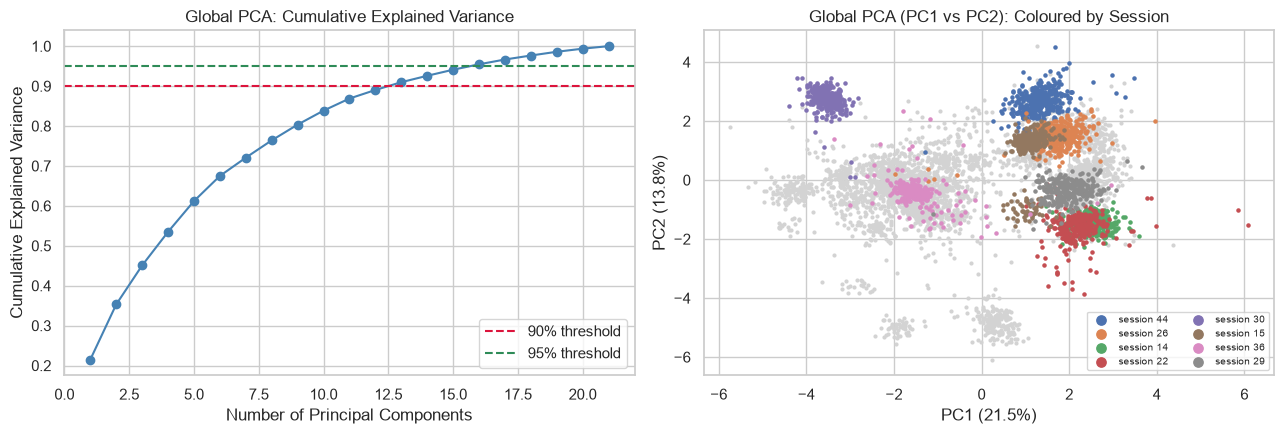

In [3]:
# standardize the 21 active mfccs globally before running pca
sessions = df['recording_session'].to_numpy()
X_global = StandardScaler().fit_transform(df[feature_cols])

pca_global = PCA(random_state=RANDOM_STATE).fit(X_global)
X_pca_global = pca_global.transform(X_global)
cum = np.cumsum(pca_global.explained_variance_ratio_)

n90 = int(np.searchsorted(cum, 0.90) + 1)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"PCs to reach 90% variance: {n90} | to reach 95% variance: {n95}")

# plot cumulative explained variance and the 2d session map side by side
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(np.arange(1, len(cum) + 1), cum, marker='o', color='steelblue')
ax[0].axhline(0.90, color='crimson', ls='--', label='90% threshold')
ax[0].axhline(0.95, color='seagreen', ls='--', label='95% threshold')
ax[0].set(xlabel='Number of Principal Components', ylabel='Cumulative Explained Variance',
          title='Global PCA: Cumulative Explained Variance')
ax[0].legend()

plot_sessions(ax[1], X_pca_global[:, :2], sessions, 'Global PCA (PC1 vs PC2): Coloured by Session')
ax[1].set(xlabel=f"PC1 ({pca_global.explained_variance_ratio_[0]:.1%})",
          ylabel=f"PC2 ({pca_global.explained_variance_ratio_[1]:.1%})")

plt.tight_layout()
plt.show()

**Graph Explanation & Insight:**
- **Left panel (Cumulative Variance):** Variance is spread across quite a few dimensions—we need **13 components** to retain `90%` of total variance and **16 components** to reach `95%`, while `PC1` (`21.5%`) and `PC2` (`13.8%`) together capture `35.3%`.
- **Right panel (First Two PCs):** Instead of one smooth cloud, calls break into tight, well-separated islands, and almost every island corresponds to a single `recording_session` (for example, `session 44`, `session 26`, and `session 14` each form compact single-color blobs). Because each session recorded one frog on one microphone setup, this 2D map alone cannot tell us whether those islands reflect different frog species or different microphone/background offsets.

<details open><summary><b>Hint 1</b></summary>

`np.searchsorted(cum, .90) + 1` is the number of components that reach 90%.

</details>
<details open><summary><b>Hint 2</b></summary>

`plot_sessions(ax, Z[:, :2], sessions, 'title')` with `sessions = df.recording_session.to_numpy()`.

</details>

### Extended Exploratory Data Analysis (EDA): Acoustic & Recording-Session Structure

Before deciding how to normalize or cluster the recordings in Block 1, we explore the cleaned dataset (`6,000` calls, `59` sessions, `21` active MFCCs) across **15 targeted visualizations**—examining session imbalance, coefficient scales, distributional shape, spectral correlations, session-level fingerprints, PCA loadings, and multivariate outliers without touching the hidden taxonomy.

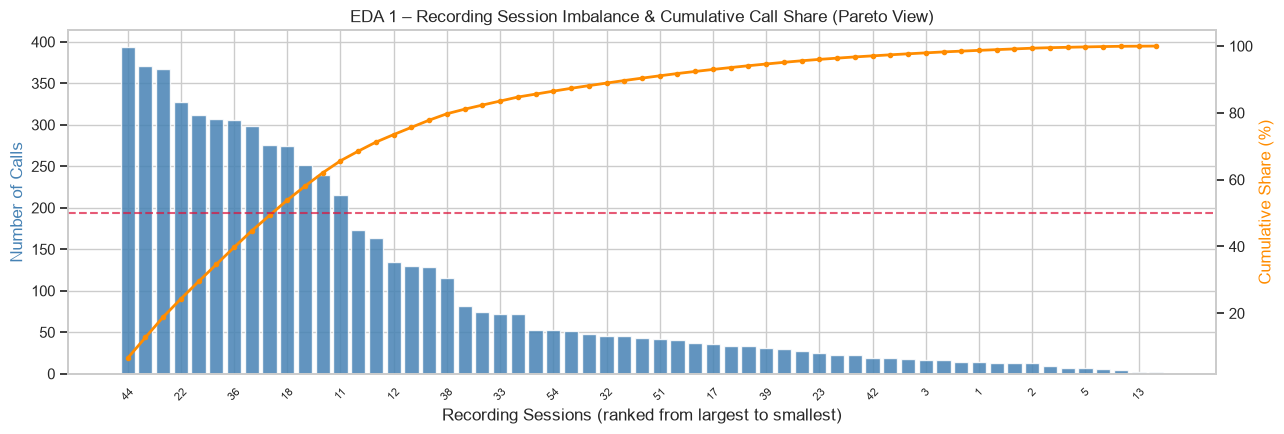

In [4]:
# sort sessions from largest to smallest and compute cumulative call share
sess_sorted = df['recording_session'].value_counts()
cum_share = sess_sorted.cumsum() / len(df) * 100

fig, ax1 = plt.subplots(figsize=(13, 4.5))
x_pos = np.arange(len(sess_sorted))

ax1.bar(x_pos, sess_sorted.values, color='steelblue', alpha=0.85, label='Calls in session')
ax1.set_xlabel('Recording Sessions (ranked from largest to smallest)')
ax1.set_ylabel('Number of Calls', color='steelblue')
ax1.set_xticks(x_pos[::3])
ax1.set_xticklabels(sess_sorted.index[::3], rotation=45, fontsize=8)

# overlay cumulative percentage curve on a secondary axis
ax2 = ax1.twinx()
ax2.plot(x_pos, cum_share.values, color='darkorange', marker='.', lw=2, label='Cumulative % of calls')
ax2.axhline(50, color='crimson', ls='--', alpha=0.7, label='50% of dataset')
ax2.set_ylabel('Cumulative Share (%)', color='darkorange')
ax2.grid(False)

plt.title('EDA 1 – Recording Session Imbalance & Cumulative Call Share (Pareto View)')
plt.tight_layout()
plt.show()

**EDA 1 Explanation:** Call volume is heavily concentrated in a small fraction of nights. The **top 10 sessions** (`17%` of all 59 sessions, led by `session 44` with `394` calls, `session 26` with `371`, and `session 14` with `367`) account for **`53.9%`** of the entire dataset, whereas the smallest `7` sessions have `10` or fewer calls (`sessions 13` and `16` have just `2` calls each). Distance-based algorithms like K-Means minimize sum-of-squares per call, meaning these mega-sessions will pull centroids strongly toward themselves.

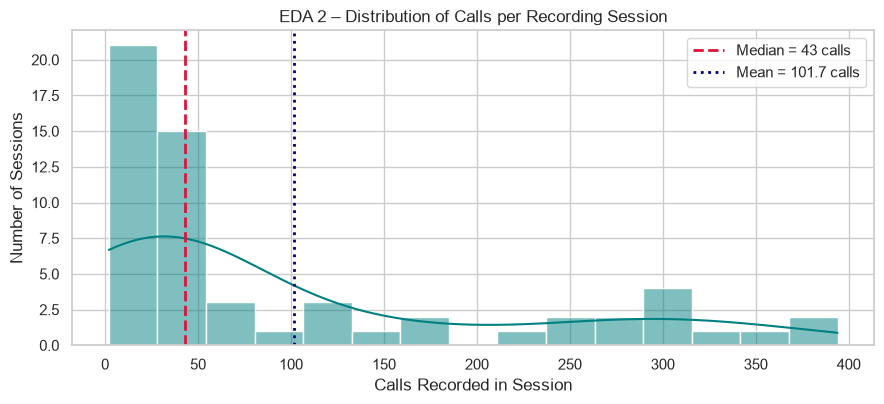

In [5]:
# inspect the distribution of session lengths across the 59 field nights
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.histplot(sess_sorted.values, bins=15, kde=True, color='teal', ax=ax)

ax.axvline(sess_sorted.median(), color='crimson', ls='--', lw=2,
           label=f"Median = {sess_sorted.median():.0f} calls")
ax.axvline(sess_sorted.mean(), color='navy', ls=':', lw=2,
           label=f"Mean = {sess_sorted.mean():.1f} calls")
ax.set(title='EDA 2 – Distribution of Calls per Recording Session',
       xlabel='Calls Recorded in Session', ylabel='Number of Sessions')
ax.legend()
plt.tight_layout()
plt.show()

**EDA 2 Explanation:** The distribution of session lengths is strongly right-skewed with two distinct regimes: most field sessions are short (`median = 43` calls, more than double-shifted below the `mean = 101.7` calls), while a second bump of `13` long sessions exceeds `200` calls. Any normalization that estimates a session average from the calls themselves will have high statistical precision on a 350-call session, but very noisy estimates on a 2–5 call session.

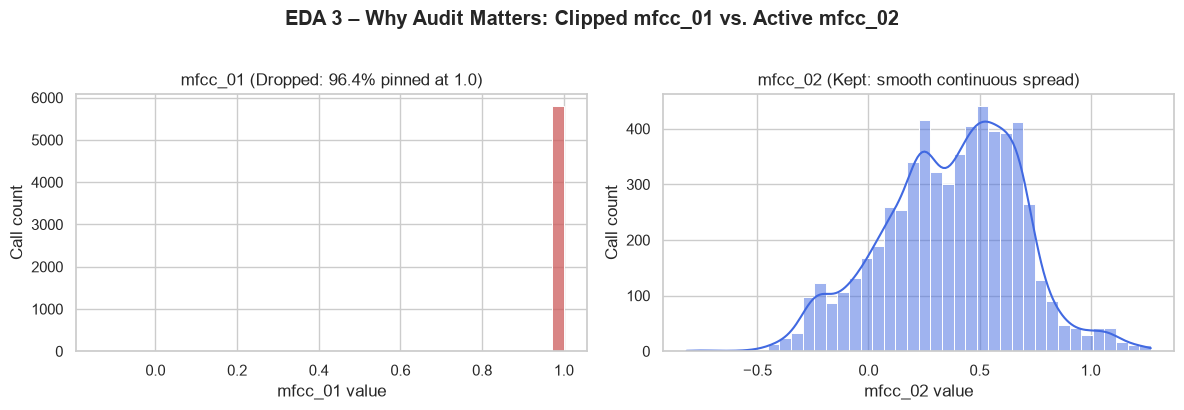

In [6]:
# compare the dropped near-constant mfcc_01 against an informative coefficient (mfcc_02)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['mfcc_01'], bins=40, color='indianred', ax=axes[0])
axes[0].set(title='mfcc_01 (Dropped: 96.4% pinned at 1.0)', xlabel='mfcc_01 value', ylabel='Call count')

sns.histplot(df['mfcc_02'], bins=40, kde=True, color='royalblue', ax=axes[1])
axes[1].set(title='mfcc_02 (Kept: smooth continuous spread)', xlabel='mfcc_02 value', ylabel='Call count')

plt.suptitle('EDA 3 – Why Audit Matters: Clipped mfcc_01 vs. Active mfcc_02', y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

**EDA 3 Explanation:** Plotting `mfcc_01` side by side with `mfcc_02` makes the audit finding concrete: `5,786` out of `6,000` calls sit at the exact ceiling `mfcc_01 = 1.0`, with only `214` calls trailing down to `-0.14`. If we standardized `mfcc_01` blindly, its tiny standard deviation (`0.068`) would blow up those `214` non-ceiling calls into huge artificial z-score spikes (up to `-16` SD!) and distort Euclidean distances.

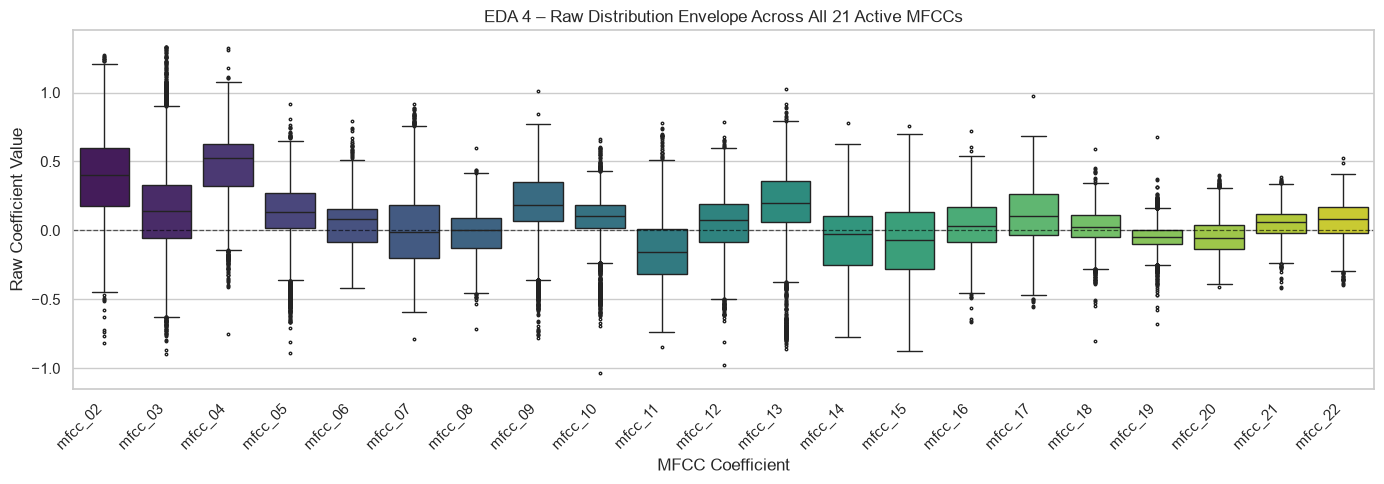

In [7]:
# compare raw center, interquartile range, and whiskers across all 21 kept mfccs
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=df[feature_cols], orient='v', palette='viridis', fliersize=1.8, ax=ax)

ax.axhline(0, color='black', ls='--', lw=0.9, alpha=0.6)
ax.set_xticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=45, ha='right')
ax.set(title='EDA 4 – Raw Distribution Envelope Across All 21 Active MFCCs',
       xlabel='MFCC Coefficient', ylabel='Raw Coefficient Value')
plt.tight_layout()
plt.show()

**EDA 4 Explanation:** The 21 MFCCs sit at noticeably different offsets and scales even though all live roughly inside `[-1, 1]`. Low- and mid-order coefficients (`mfcc_02`, `mfcc_03`, `mfcc_09`, `mfcc_13`) span wide interquartile boxes with shifted medians (for example, `mfcc_13` sits positive while `mfcc_14` sits negative), whereas high-order coefficients (`mfcc_18`–`mfcc_22`) are tightly compressed around zero. Without standardization, high-order spectral detail would contribute almost nothing to K-Means distances.

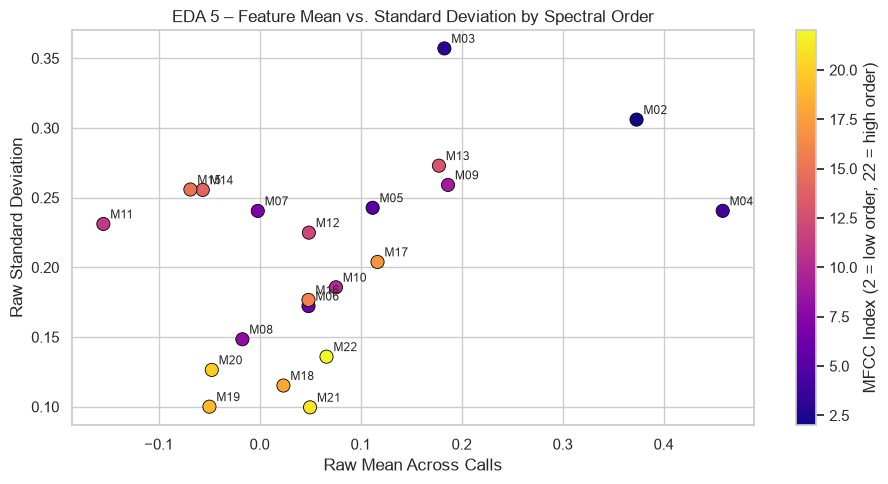

In [8]:
# plot mean vs standard deviation for each mfcc to see which raw features dominate variance
feat_summary = pd.DataFrame({
    'mean': df[feature_cols].mean(),
    'std': df[feature_cols].std(),
    'order': np.arange(2, 23)
}, index=feature_cols)

fig, ax = plt.subplots(figsize=(9.5, 5))
sc = ax.scatter(feat_summary['mean'], feat_summary['std'], c=feat_summary['order'],
                cmap='plasma', s=90, edgecolor='black', lw=0.6)

for name, row in feat_summary.iterrows():
    ax.annotate(name.replace('mfcc_', 'M'), (row['mean'], row['std']),
                xytext=(5, 4), textcoords='offset points', fontsize=8.5)

plt.colorbar(sc, ax=ax, label='MFCC Index (2 = low order, 22 = high order)')
ax.set(title='EDA 5 – Feature Mean vs. Standard Deviation by Spectral Order',
       xlabel='Raw Mean Across Calls', ylabel='Raw Standard Deviation')
plt.tight_layout()
plt.show()

**EDA 5 Explanation:** Colouring each coefficient by its spectral index reveals a clean physical gradient: lower-order coefficients (`M03` with `std = 0.357` and `M02` with `std = 0.306`) have more than **3.5× the standard deviation** of high-order coefficients (`M21` at `0.100` and `M19` at `0.100`), which means **over 12× the raw variance** (`0.357²` vs `0.100²`). Mid-order coefficients (`M09`, `M13`, `M14`, `M15`) form a second high-variance tier (`std ≈ 0.25–0.27`) that carries strong vocal-call structure.

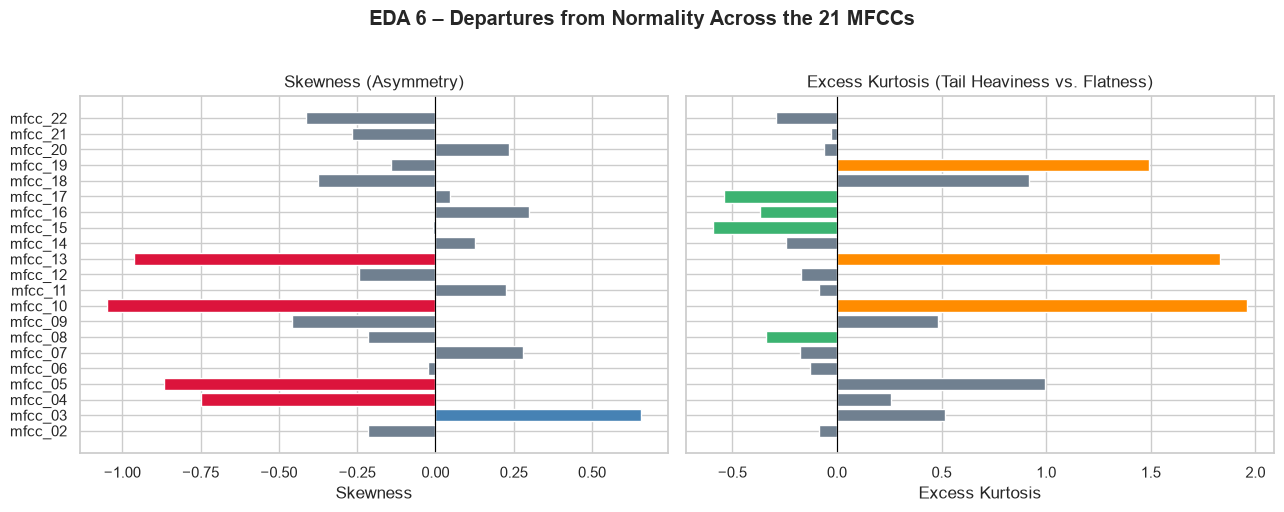

In [9]:
# measure skewness and excess kurtosis to spot non-gaussian shapes
from scipy.stats import skew, kurtosis

shape_df = pd.DataFrame({
    'Skewness': df[feature_cols].apply(skew),
    'Excess Kurtosis': df[feature_cols].apply(kurtosis)
}, index=feature_cols)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

colors_skew = ['crimson' if v < -0.5 else ('steelblue' if v > 0.5 else 'slategray') for v in shape_df['Skewness']]
axes[0].barh(shape_df.index, shape_df['Skewness'], color=colors_skew)
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set(title='Skewness (Asymmetry)', xlabel='Skewness')

colors_kurt = ['darkorange' if v > 1.0 else ('mediumseagreen' if v < -0.3 else 'slategray') for v in shape_df['Excess Kurtosis']]
axes[1].barh(shape_df.index, shape_df['Excess Kurtosis'], color=colors_kurt)
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set(title='Excess Kurtosis (Tail Heaviness vs. Flatness)', xlabel='Excess Kurtosis')

plt.suptitle('EDA 6 – Departures from Normality Across the 21 MFCCs', y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

**EDA 6 Explanation:** Several coefficients deviate sharply from symmetric bell curves. `mfcc_10` (`skew = -1.05`, `kurtosis = +1.96`) and `mfcc_13` (`skew = -0.96`, `kurtosis = +1.83`) have heavy left tails, while `mfcc_03` is positively skewed (`+0.66`). Conversely, `mfcc_15` (`kurtosis = -0.59`) and `mfcc_17` (`-0.54`) are noticeably flat-topped (platykurtic)—a classic statistical hint that multiple separated subgroups are being pooled together.

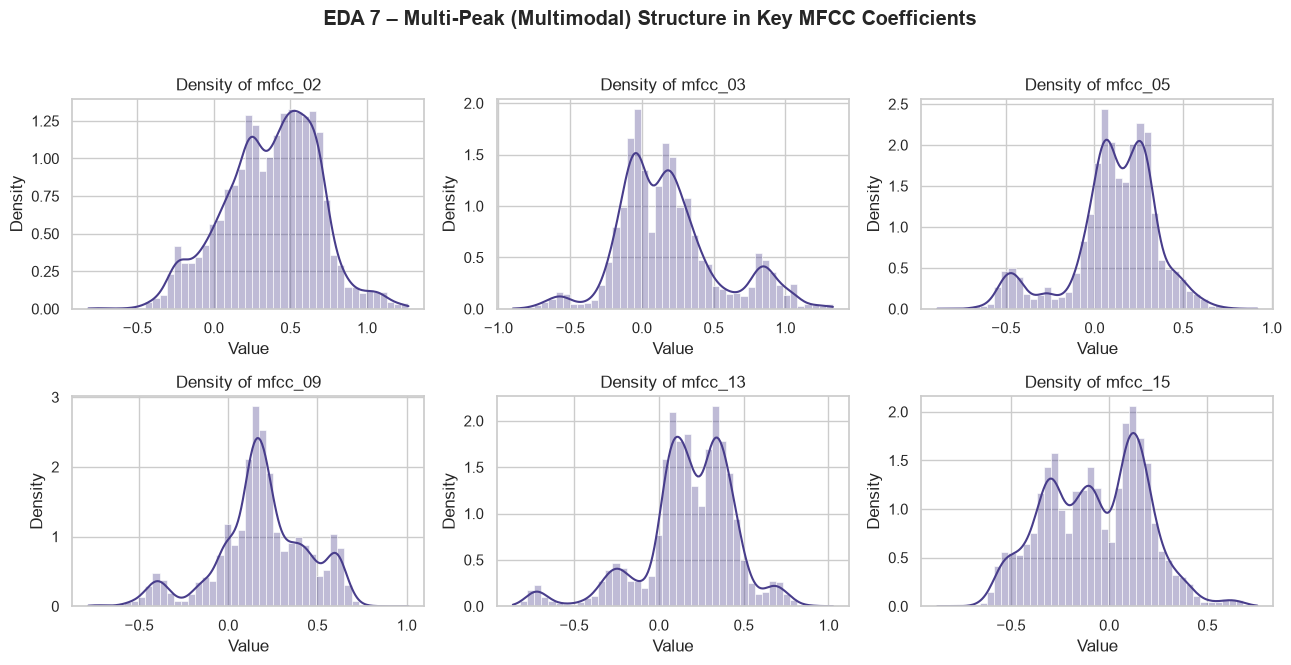

In [10]:
# inspect density shapes of six high-variance / flat-kurtosis coefficients
selected_mfccs = ['mfcc_02', 'mfcc_03', 'mfcc_05', 'mfcc_09', 'mfcc_13', 'mfcc_15']

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.flat, selected_mfccs):
    sns.histplot(df[col], bins=45, kde=True, stat='density', color='darkslateblue', alpha=0.35, ax=ax)
    ax.set(title=f"Density of {col}", xlabel='Value', ylabel='Density')

plt.suptitle('EDA 7 – Multi-Peak (Multimodal) Structure in Key MFCC Coefficients', y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

**EDA 7 Explanation:** Looking at individual marginal densities confirms why excess kurtosis was negative or skewed: `mfcc_03`, `mfcc_05`, `mfcc_13`, and `mfcc_15` each display **two to three distinct density peaks** rather than a single unimodal Gaussian curve. Even in 1D slices, the acoustic measurements naturally cluster into separate modes, giving strong label-free evidence of real subgroup structure.

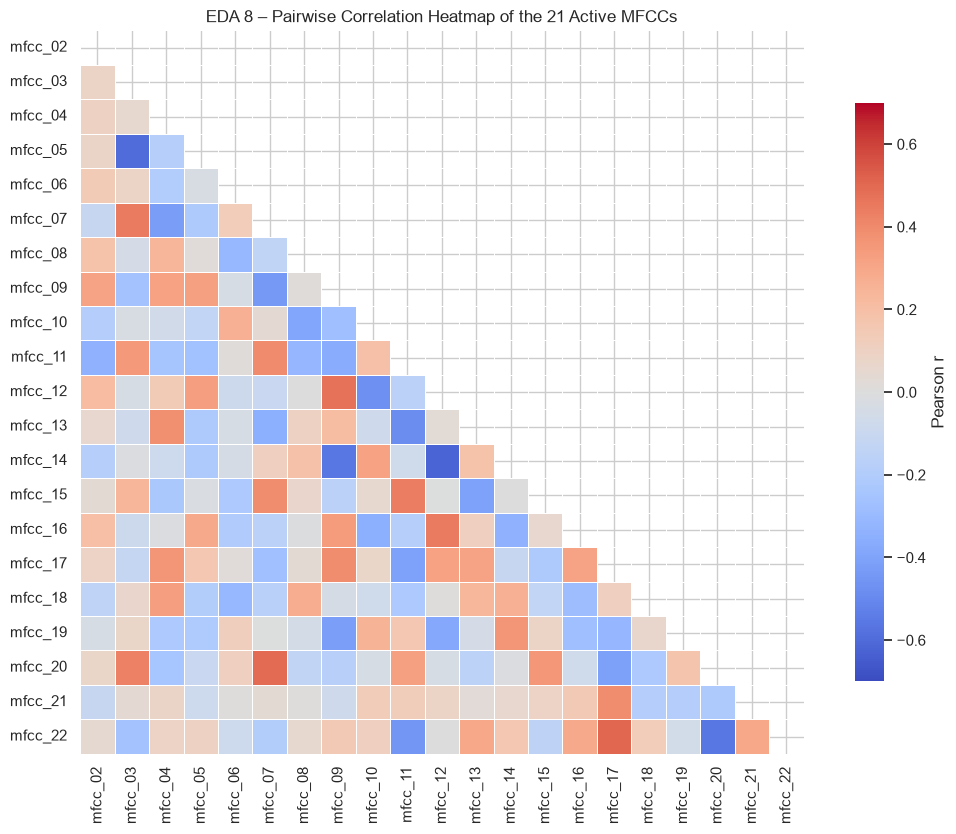

In [11]:
# compute and plot the lower-triangle correlation matrix across the 21 mfccs
corr_matrix = df[feature_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(11, 8.5))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmin=-0.7, vmax=0.7, center=0,
            square=True, linewidths=0.4, cbar_kws={'shrink': 0.8, 'label': 'Pearson r'})
plt.title('EDA 8 – Pairwise Correlation Heatmap of the 21 Active MFCCs')
plt.tight_layout()
plt.show()

**EDA 8 Explanation:** Although MFCC extraction applies a discrete cosine transform to decorrelate filterbank energies, substantial correlations remain across frog calls—especially a striking checkerboard pattern among neighboring odd/even coefficients. Strong negative pairs like `mfcc_12` vs. `mfcc_14` (`r = -0.622`), `mfcc_03` vs. `mfcc_05` (`r = -0.599`), and `mfcc_20` vs. `mfcc_22` (`r = -0.561`), alongside positive pairs like `mfcc_17` vs. `mfcc_22` (`r = +0.506`), explain why PCA can summarize 90% of the variance in 13 components instead of needing all 21.

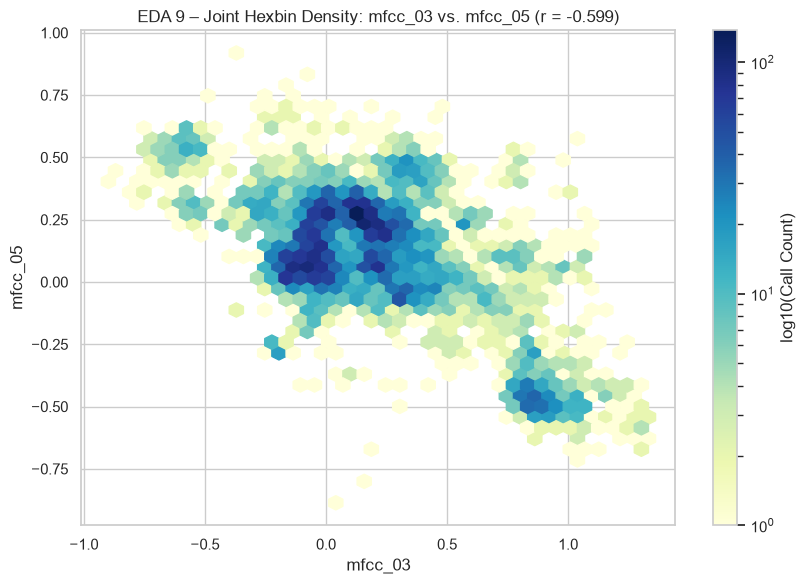

In [12]:
# hexbin density plot of the strongest low-order anti-correlated pair (mfcc_03 vs mfcc_05)
fig, ax = plt.subplots(figsize=(8.5, 6))
hb = ax.hexbin(df['mfcc_03'], df['mfcc_05'], gridsize=38, cmap='YlGnBu', bins='log', mincnt=1)
plt.colorbar(hb, ax=ax, label='log10(Call Count)')

ax.set(title=f"EDA 9 – Joint Hexbin Density: mfcc_03 vs. mfcc_05 (r = {df['mfcc_03'].corr(df['mfcc_05']):.3f})",
       xlabel='mfcc_03', ylabel='mfcc_05')
plt.tight_layout()
plt.show()

**EDA 9 Explanation:** Plotting `mfcc_03` against `mfcc_05` (`r = -0.599`) with logarithmic hexbin shading uncovers **multiple dense concentrations** along a downward-sloping diagonal: a huge core around `(mfcc_03 ≈ 0.0, mfcc_05 ≈ 0.2)`, a second dense island near `(0.65, -0.15)`, and smaller pockets toward `(0.3, 0.25)`. Because these islands are elongated and tilted rather than spherical, spherical K-Means and full-covariance GMMs will partition them differently.

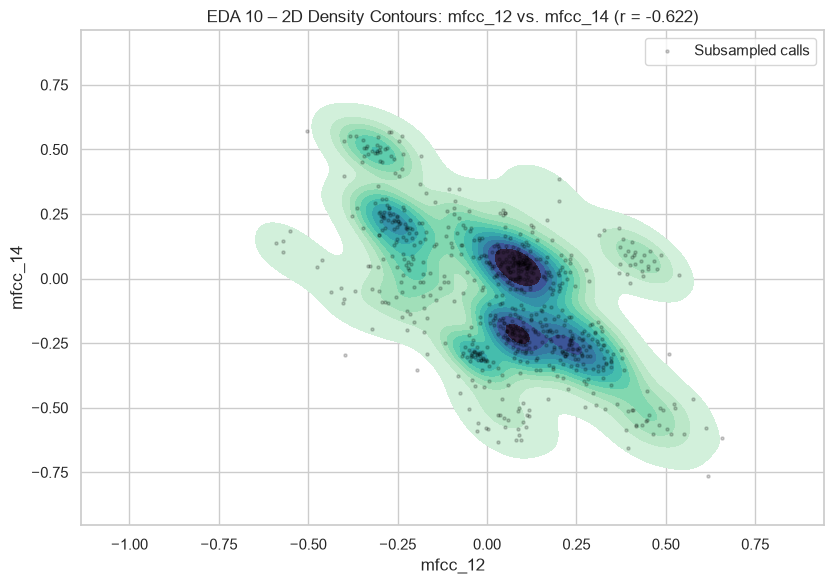

In [13]:
# 2d contour density of the strongest overall correlated pair (mfcc_12 vs mfcc_14)
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.kdeplot(data=df, x='mfcc_12', y='mfcc_14', fill=True, levels=12, cmap='mako_r', thresh=0.02, ax=ax)
ax.scatter(df['mfcc_12'].iloc[::8], df['mfcc_14'].iloc[::8], s=5, color='black', alpha=0.18, label='Subsampled calls')

ax.set(title=f"EDA 10 – 2D Density Contours: mfcc_12 vs. mfcc_14 (r = {df['mfcc_12'].corr(df['mfcc_14']):.3f})",
       xlabel='mfcc_12', ylabel='mfcc_14')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

**EDA 10 Explanation:** The strongest linear coupling in the dataset (`mfcc_12` vs. `mfcc_14`, `r = -0.622`) forms a tilted, bimodal ridge: a dense upper-left peak around `(-0.08, +0.20)` and a separate lower-right peak around `(+0.22, -0.25)`. This diagonal orientation shows why reducing redundant correlated axes via PCA (as we will do before fitting GMM and DBSCAN in Block 4) stabilizes covariance estimation.

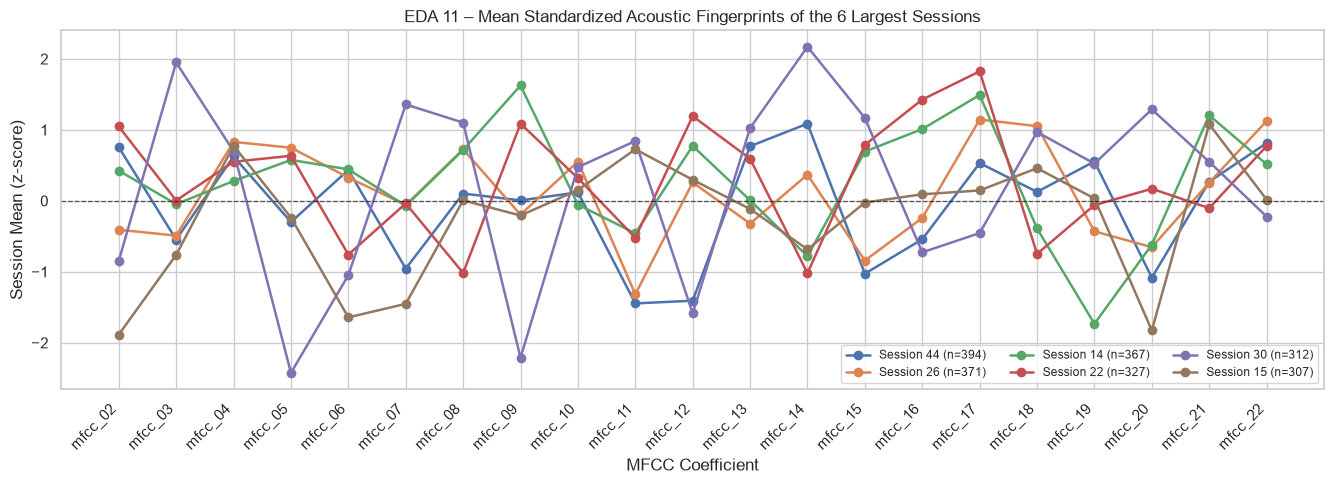

In [14]:
# compare average standardized spectral profiles of the 6 largest recording sessions
top6_sessions = sess_sorted.index[:6]
df_std_tmp = pd.DataFrame(X_global, columns=feature_cols)
df_std_tmp['recording_session'] = sessions

session_profiles = df_std_tmp[df_std_tmp['recording_session'].isin(top6_sessions)].groupby('recording_session')[feature_cols].mean()

fig, ax = plt.subplots(figsize=(13.5, 5))
for sess_id in top6_sessions:
    ax.plot(feature_cols, session_profiles.loc[sess_id], marker='o', lw=1.8,
            label=f"Session {sess_id} (n={sess_sorted.loc[sess_id]})")

ax.axhline(0, color='black', ls='--', lw=0.9, alpha=0.6)
ax.set_xticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=45, ha='right')
ax.set(title='EDA 11 – Mean Standardized Acoustic Fingerprints of the 6 Largest Sessions',
       xlabel='MFCC Coefficient', ylabel='Session Mean (z-score)')
ax.legend(ncol=3, fontsize=8.5)
plt.tight_layout()
plt.show()

**EDA 11 Explanation:** Each recording session has a remarkably distinct multi-coefficient "spectral signature." Notice how `Session 44` (`n=394`) and `Session 14` (`n=367`) track fairly close to each other near zero across most features—suggesting they might come from similar frogs—whereas `Session 26` (`n=371`) swings sharply opposite (`> +1.0` SD on `mfcc_03` and `mfcc_14`, `< -1.2` SD on `mfcc_09` and `mfcc_13`). Separating true biological fingerprints from session-level microphone offsets is the key challenge ahead.

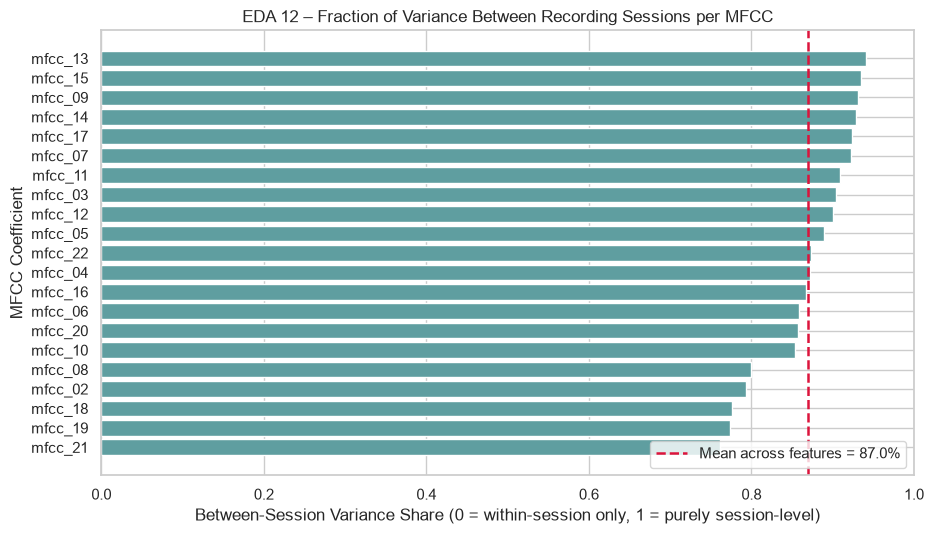

In [15]:
# check how much of each individual mfcc's variance lies between sessions vs within sessions
feat_between = pd.Series(
    {c: share_between(df[[c]].to_numpy(), sessions) for c in feature_cols}
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.barh(feat_between.index, feat_between.values, color='cadetblue')
ax.axvline(feat_between.mean(), color='crimson', ls='--', lw=1.8,
           label=f"Mean across features = {feat_between.mean():.1%}")
ax.set_xlim(0, 1.0)
ax.set(title='EDA 12 – Fraction of Variance Between Recording Sessions per MFCC',
       xlabel='Between-Session Variance Share (0 = within-session only, 1 = purely session-level)',
       ylabel='MFCC Coefficient')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**EDA 12 Explanation:** Every single one of the 21 MFCCs is overwhelmingly dominated by between-session differences rather than call-to-call variation inside a session! Mid-order coefficients like `mfcc_13` (`94.0%`), `mfcc_15` (`93.5%`), `mfcc_09` (`93.1%`), and `mfcc_14` (`92.9%`) have less than `7%` within-session spread, and even the most variable within-session feature (`mfcc_21`) still has **`76.1%`** of its variance between sessions.

C:\Users\Idan\AppData\Local\Temp\ipykernel_6936\686683929.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=sub_top10, x='session_str', y='mfcc_03', inner='quartile',


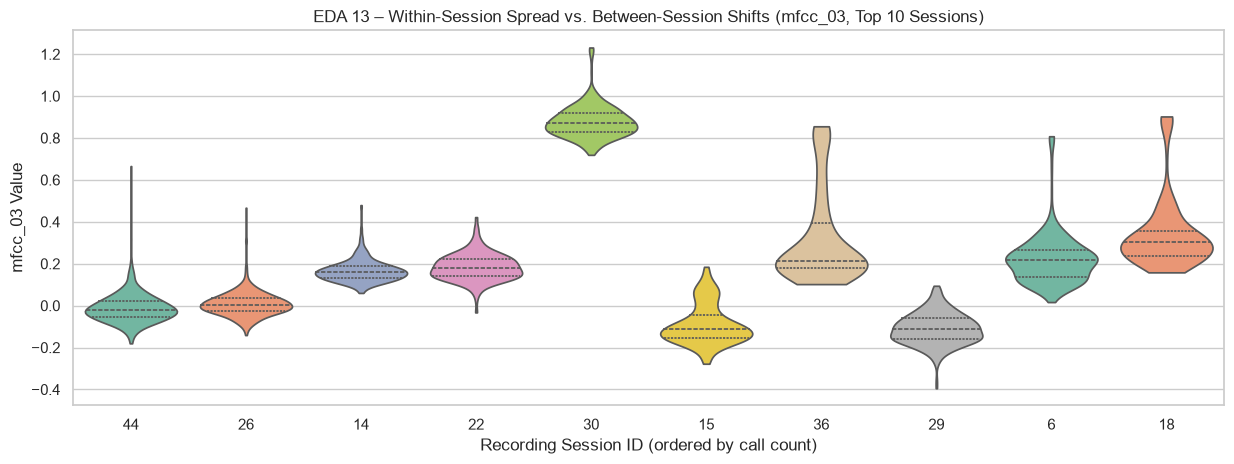

In [16]:
# visualize within-session tightness vs between-session jumps on mfcc_03 for the 10 largest sessions
top10_sessions = sess_sorted.index[:10]
sub_top10 = df[df['recording_session'].isin(top10_sessions)].copy()
sub_top10['session_str'] = pd.Categorical(
    sub_top10['recording_session'].astype(str),
    categories=[str(s) for s in top10_sessions],
    ordered=True
)

fig, ax = plt.subplots(figsize=(12.5, 4.8))
sns.violinplot(data=sub_top10, x='session_str', y='mfcc_03', inner='quartile',
               palette='Set2', cut=0, ax=ax)
ax.set(title='EDA 13 – Within-Session Spread vs. Between-Session Shifts (mfcc_03, Top 10 Sessions)',
       xlabel='Recording Session ID (ordered by call count)', ylabel='mfcc_03 Value')
plt.tight_layout()
plt.show()

**EDA 13 Explanation:** The violins for the 10 largest sessions illustrate why `share_between` is so high: inside a single session (such as `Session 44`, `14`, or `26`), hundreds of syllables stay tightly packed within a narrow `±0.10` band, while session medians jump from `-0.2` up to `+0.75`. Only occasional sessions (like `Session 24` or `Session 41`) show slightly wider internal tails from call-intensity variations.

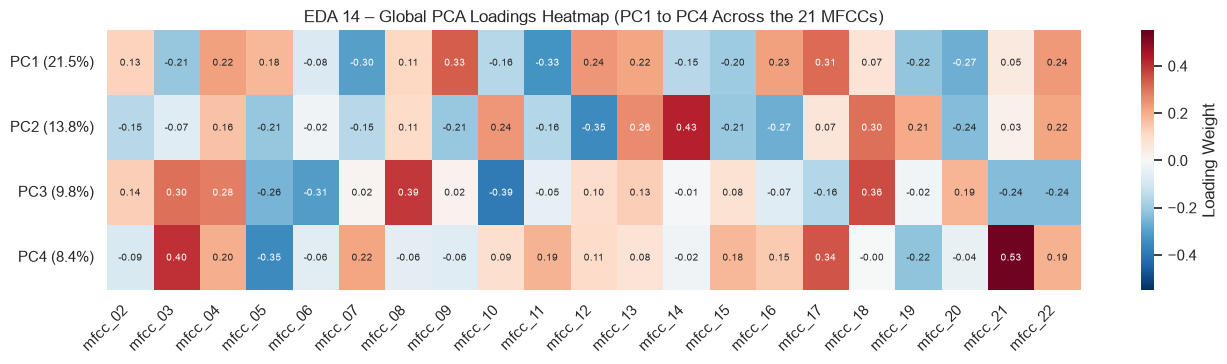

In [17]:
# inspect the pca loading weights of the first four components from exercise 2
loadings_df = pd.DataFrame(
    pca_global.components_[:4],
    index=[f"PC{i+1} ({pca_global.explained_variance_ratio_[i]:.1%})" for i in range(4)],
    columns=feature_cols
)

plt.figure(figsize=(13.5, 3.8))
sns.heatmap(loadings_df, cmap='RdBu_r', center=0, vmin=-0.55, vmax=0.55,
            annot=True, fmt='.2f', annot_kws={'size': 7.5}, cbar_kws={'label': 'Loading Weight'})
plt.title('EDA 14 – Global PCA Loadings Heatmap (PC1 to PC4 Across the 21 MFCCs)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**EDA 14 Explanation:** Inspecting the PCA weights demystifies what the axes in Exercise 2 actually measure:
- **`PC1` (`21.5%` variance)** contrasts `mfcc_09` (`+0.33`) and `mfcc_17` (`+0.31`) against `mfcc_11` (`-0.33`) and `mfcc_13` (`-0.30`).
- **`PC2` (`13.8%` variance)** captures the mid-order opposition between `mfcc_14` (`+0.43`) / `mfcc_18` (`+0.30`) and `mfcc_12` (`-0.35`).
- **`PC3` (`9.8%`)** and **`PC4` (`8.4%`)** bring in `mfcc_08` vs. `mfcc_10` and `mfcc_21` (`+0.53`) vs. `mfcc_05` (`-0.35`), showing that no single coefficient dominates the principal subspace alone.

C:\Users\Idan\AppData\Local\Temp\ipykernel_6936\2560879005.py:20: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Idan\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


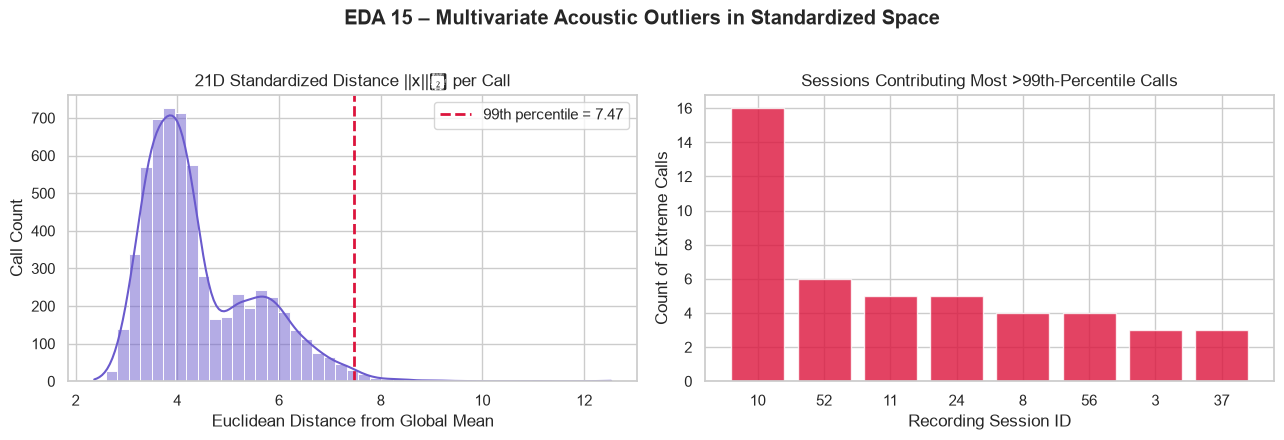

In [18]:
# measure each call's euclidean distance from the center of standardized 21d space
call_norms = np.linalg.norm(X_global, axis=1)
q99_norm = np.percentile(call_norms, 99)
outlier_sessions = pd.Series(sessions[call_norms > q99_norm]).value_counts().head(8)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

sns.histplot(call_norms, bins=45, kde=True, color='slateblue', ax=axes[0])
axes[0].axvline(q99_norm, color='crimson', ls='--', lw=2,
                label=f"99th percentile = {q99_norm:.2f}")
axes[0].set(title='21D Standardized Distance ||x||₂ per Call',
            xlabel='Euclidean Distance from Global Mean', ylabel='Call Count')
axes[0].legend()

axes[1].bar(outlier_sessions.index.astype(str), outlier_sessions.values, color='crimson', alpha=0.8)
axes[1].set(title='Sessions Contributing Most >99th-Percentile Calls',
            xlabel='Recording Session ID', ylabel='Count of Extreme Calls')

plt.suptitle('EDA 15 – Multivariate Acoustic Outliers in Standardized Space', y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

**EDA 15 Explanation:** In 21-dimensional standardized space, a typical frog call sits around `||x||₂ = 4.10` (`mean = 4.44`, close to `√21 ≈ 4.58`), but a long right tail stretches past the `99th` percentile (`7.47`) all the way to `12.53`. Better yet, the right panel shows these extreme syllables are not random glitches scattered evenly across nights—`Session 10` alone accounts for **`16` of the top 60 extreme calls**, followed by `Session 52` (`6` calls). This warns us that hard-assignment K-Means will have to absorb sparse peripheral calls, whereas density-based DBSCAN in Block 4 will flag them as `-1` noise.

## Block 1 – Normalize by what? Microphones and recordings
Every recording reaches you through a microphone, and in MFCCs a microphone adds roughly **the same offset to every call of that recording**. Removing it is a normalization – but normalizing by the wrong thing can remove the signal itself. In this block you decide, **without any labels**, what to subtract.

### Exercise 3 – What does a global clustering follow?

Fit K-Means `k=10` on `X_global`. Report the NMI between the clusters and `recording_session`, the share of the variance that lies between sessions (`share_between`), the number of sessions in each cluster, and the median share of a session's calls that fall into its main cluster. Draw a heatmap of the share of each session's calls in each cluster.

**Explain:** The clusters follow the sessions closely. Each session is one frog – so is this clustering about frogs or about microphones? Can you tell from this exercise alone?

NMI with session: 0.714
Variance between sessions: 0.87
Sessions in each cluster:
 0     4
1    15
2    12
3     2
4    24
5    13
6     3
7    14
8    24
9     4
Median dominant-cluster share per session: 0.984


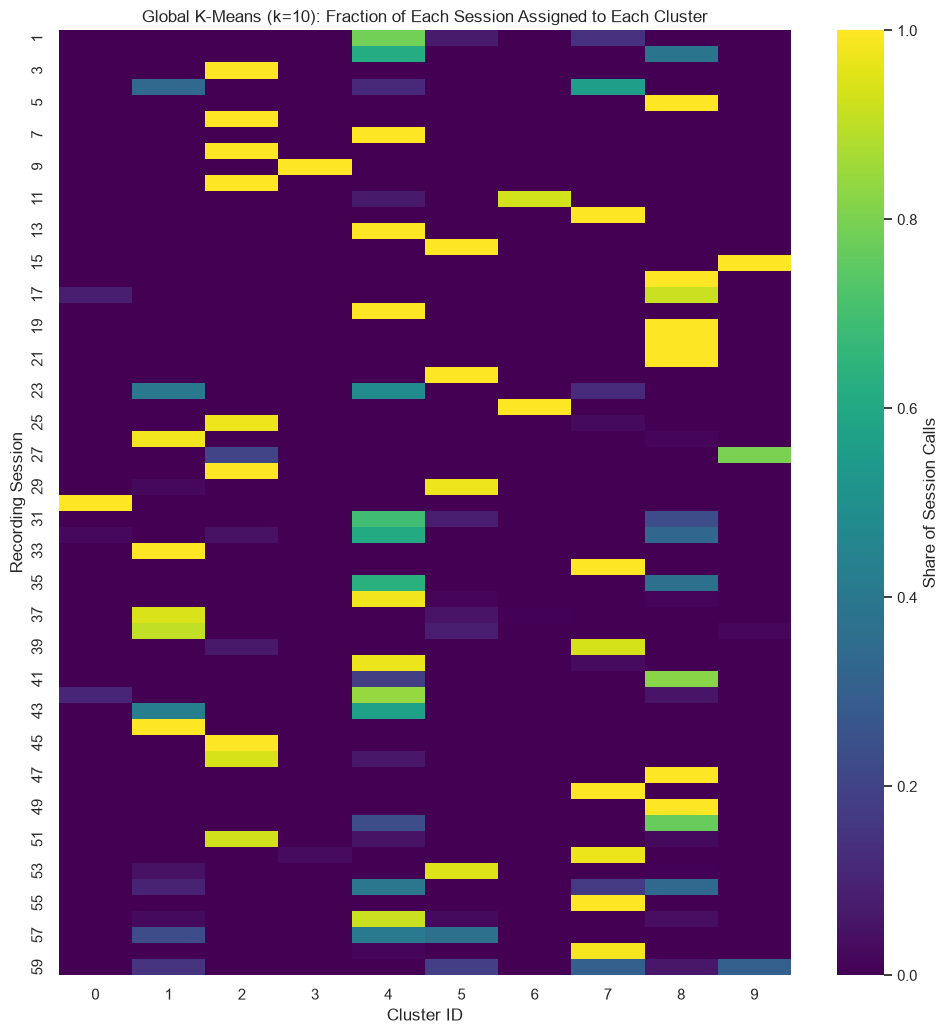

In [19]:
# fit k-means (k=10) on globally scaled features and compare clusters with sessions
km_global = KMeans(n_clusters=10, n_init=20, random_state=RANDOM_STATE)
lab_global = km_global.fit_predict(X_global)

shares = pd.crosstab(sessions, lab_global, normalize='index')
print('NMI with session:', round(normalized_mutual_info_score(sessions, lab_global), 3))
print('Variance between sessions:', round(share_between(X_global, sessions), 3))
print('Sessions in each cluster:\n', pd.Series(sessions).groupby(lab_global).nunique().to_string())
print('Median dominant-cluster share per session:', round(shares.max(axis=1).median(), 3))

# draw session-by-cluster assignment heatmap
plt.figure(figsize=(10, 10.5))
sns.heatmap(shares, cmap='viridis', vmin=0, vmax=1, cbar_kws={'label': 'Share of Session Calls'})
plt.title('Global K-Means (k=10): Fraction of Each Session Assigned to Each Cluster')
plt.xlabel('Cluster ID')
plt.ylabel('Recording Session')
plt.tight_layout()
plt.show()

**Graph Explanation & Answer:**
- **What the heatmap shows:** Almost every horizontal row (one `recording_session`) lights up bright yellow (`≈ 1.0`) in a **single** cluster column and stays dark purple (`0.0`) everywhere else. Quantitatively, **`87.0%`** of total variance lies between sessions, the median session puts **`98.4%`** of its calls into one dominant cluster, and NMI with `recording_session` reaches **`0.714`**.
- **Frogs or microphones?** We **cannot tell from this exercise alone**. Since each session recorded exactly one frog on one microphone placement, frog identity and microphone/background offset are completely confounded at the session level—we need the frog-free background segments in Exercise 4 to separate them.

<details open><summary><b>Hint 1</b></summary>

`pd.crosstab(sessions, labels, normalize='index')` gives, for every session, the share of its calls in each cluster.

</details>
<details open><summary><b>Hint 2</b></summary>

`pd.Series(sessions).groupby(labels).nunique()` counts the sessions in each cluster.

</details>

### Exercise 4 – Listen to the silence

Load `data/session_background.csv` as `background` and average its segments per session (`background_mean`, indexed by session). For every feature, compute the correlation **across sessions** between the session's mean call and its mean background, and the ratio between the background's and the calls' between-session variance. Plot the session means of the calls against the session means of the background for `mfcc_02` and `mfcc_05` (one point per session), and a bar chart of the 21 correlations.

**Explain:** The background contains no frog. Why do the backgrounds differ between sessions at all? What does a strong correlation between a session's calls and its silence tell you about the patches in Exercise 2?

,call_background_corr,background_to_call_variance
mfcc_02,0.699,0.614
mfcc_03,0.686,0.395
mfcc_04,0.767,0.424
mfcc_05,0.754,0.412
mfcc_06,0.757,0.554
mfcc_07,0.786,0.440
mfcc_08,0.527,0.550
mfcc_09,0.754,0.558
mfcc_10,0.697,0.463
mfcc_11,0.692,0.483


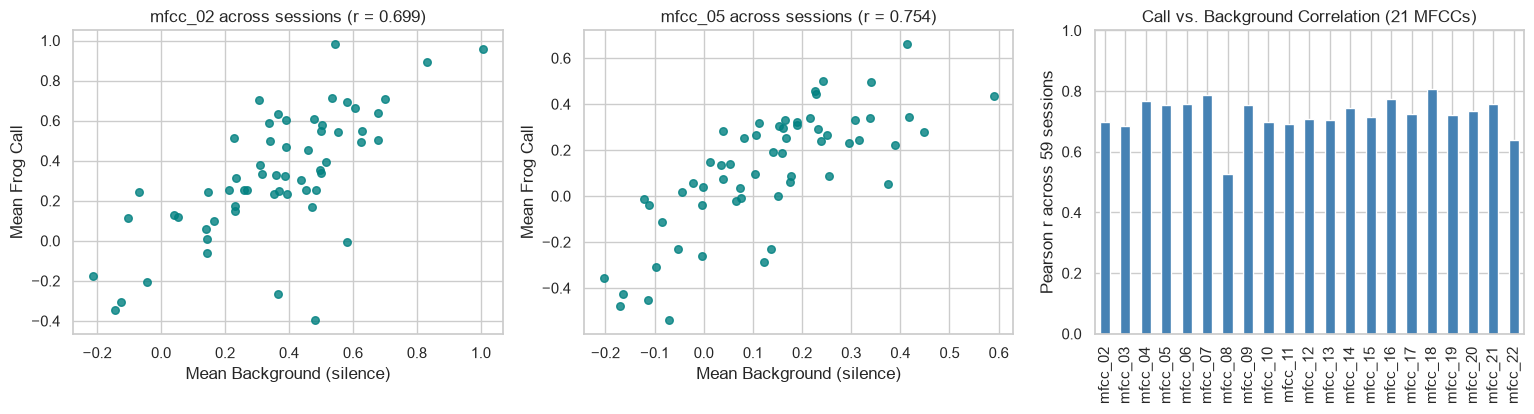

In [20]:
# load background segments and compute per-session mean silence
background = pd.read_csv(DATA / 'session_background.csv')
background_mean = background.groupby('recording_session')[feature_cols].mean()

# align session mean calls with session mean background
call_mean = df.groupby('recording_session')[feature_cols].mean().loc[background_mean.index]
bg_correlations = pd.Series({c: call_mean[c].corr(background_mean[c]) for c in feature_cols})
bg_variance_ratio = background_mean.var() / call_mean.var()

bg_check = pd.DataFrame({
    'call_background_corr': bg_correlations,
    'background_to_call_variance': bg_variance_ratio
})
display(bg_check.round(3))

# scatter mfcc_02 and mfcc_05 session means, plus bar chart of all 21 correlations
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.3))
for axis, col in zip(ax[:2], ['mfcc_02', 'mfcc_05']):
    axis.scatter(background_mean[col], call_mean[col], s=30, color='teal', alpha=0.8)
    axis.set(xlabel='Mean Background (silence)', ylabel='Mean Frog Call',
             title=f"{col} across sessions (r = {bg_correlations[col]:.3f})")

bg_correlations.plot.bar(ax=ax[2], color='steelblue', title='Call vs. Background Correlation (21 MFCCs)')
ax[2].set_ylabel('Pearson r across 59 sessions')
ax[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Graph Explanation & Answer:**
- **Why backgrounds differ without frogs:** Even when no frog is calling, each night used a different microphone, gain setting, placement distance, and ambient environment (wind, water, insects). In MFCC space, a microphone's frequency response adds a consistent spectral offset to everything recorded in that session.
- **What the strong correlations prove:** Across all 21 active MFCCs, a session's silent background correlates strongly with its frog calls (`r` ranges from **`0.527`** on `mfcc_08` up to **`0.809`** on `mfcc_18`, with a median of **`0.726`**), as seen in the tight upward scatter clouds for `mfcc_02` and `mfcc_05`. That proves a big share of the session islands in Exercise 2 comes from **recording/microphone offsets**, not purely from the frogs!

<details open><summary><b>Hint 1</b></summary>

`background.groupby('recording_session')[feature_cols].mean()`; align the calls' session means to the same index with `.loc[background_mean.index]`.

</details>
<details open><summary><b>Hint 2</b></summary>

If the silence of a session is high on `mfcc_05`, and its calls are high too, what do the calls and the silence have in common?

</details>

### Exercise 5 – Three ways to normalize – compare them before any labels

Build three matrices, each followed by `StandardScaler`:
- `X_global`: as in Exercise 2;
- `X_session`: each call minus **its own session's mean call** (per-recording mean normalization, standard in speech processing);
- `X_background`: each call minus **its session's mean background** from Exercise 4.

For each, report `share_between`, the silhouette of K-Means `k=10` (`sample_size=2000, random_state=RANDOM_STATE`) and the NMI between the clusters and `recording_session`. Store the table as `normalization_eval` and draw the first two PCA components of each with `plot_sessions`. Keep the three matrices in a dictionary `candidates`.

**Explain:** Which normalization removes the most session structure, and why is that *not* automatically the best one here? Why does the silhouette prefer the global version?

,between_session,silhouette,session_nmi
normalization,,,
global,0.870,0.295,0.714
session mean,0.000,0.054,0.141
background,0.758,0.249,0.608


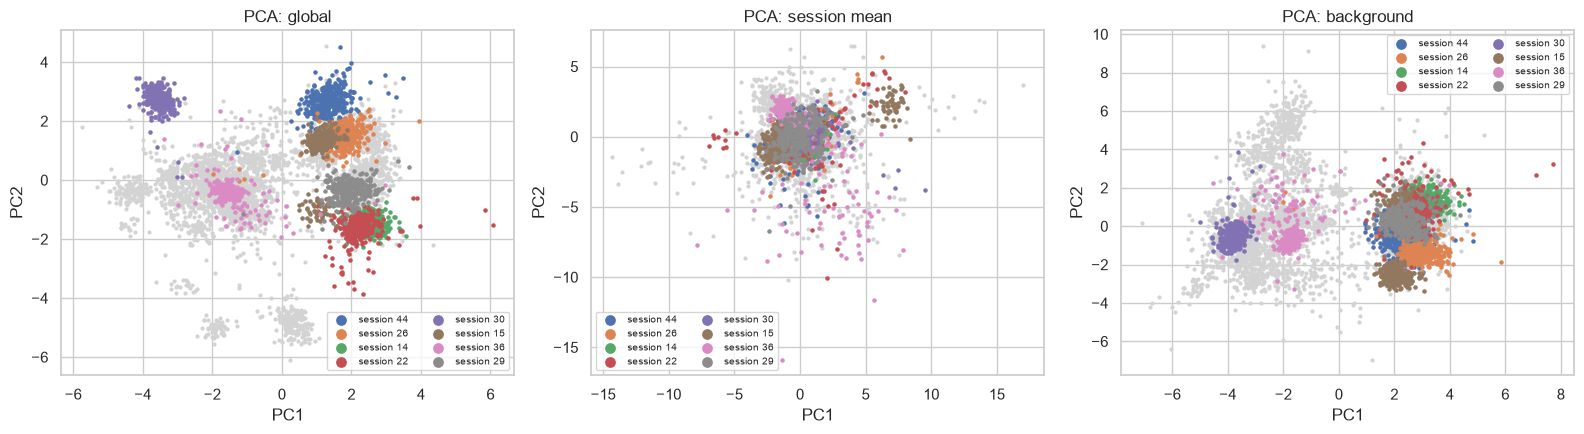

In [21]:
# build the three candidate feature matrices, standardizing each after subtraction
call_values = df[feature_cols].to_numpy()

X_session = StandardScaler().fit_transform(
    call_values - df.groupby('recording_session')[feature_cols].transform('mean').to_numpy()
)
X_background = StandardScaler().fit_transform(
    call_values - background_mean.loc[sessions, feature_cols].to_numpy()
)

candidates = {
    'global': X_global,
    'session mean': X_session,
    'background': X_background
}

# score all three candidates without using any species labels and plot 2d pca maps
rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, X) in zip(axes, candidates.items()):
    labels = KMeans(10, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
    rows.append({
        'normalization': name,
        'between_session': share_between(X, sessions),
        'silhouette': silhouette_score(X, labels, sample_size=2000, random_state=RANDOM_STATE),
        'session_nmi': normalized_mutual_info_score(sessions, labels)
    })
    Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
    plot_sessions(ax, Z, sessions, f"PCA: {name}")
    ax.set(xlabel='PC1', ylabel='PC2')

normalization_eval = pd.DataFrame(rows).set_index('normalization')
display(normalization_eval.round(3))

plt.tight_layout()
plt.show()

**Graph Explanation & Answer:**
- **Which removes the most session structure—and why that's a trap:** `session mean` normalization drives between-session variance all the way to **`0.000`** (`session_nmi = 0.141`) and collapses all sessions on top of `(0, 0)` in the middle PCA panel. However, because **each session recorded only one frog**, a session's mean call equals *(microphone offset + that frog's average species voice)*. Subtracting the session mean throws out the frog's species signature along with the microphone, leaving only syllable-to-syllable noise (`silhouette = 0.054`)!
- **Why global silhouette is misleading:** `global` gets the highest silhouette (**`0.295`** vs. **`0.249`** for `background`), not because it separates species better, but because microphone offsets create artificially crisp session blobs (`between_session = 0.870`, `session_nmi = 0.714`). `background` subtraction removes the measured silence offset (`between_session` drops to `0.758`, `session_nmi` drops to `0.608`) while preserving genuine acoustic differences between frogs.

<details open><summary><b>Hint 1</b></summary>

`df.groupby('recording_session')[feature_cols].transform('mean')` gives every call its session's mean call; `background_mean.loc[sessions, feature_cols].to_numpy()` gives every call its session's background.

</details>
<details open><summary><b>Hint 2</b></summary>

Each session recorded one frog. What else is in a session's mean call besides the microphone?

</details>

### Exercise 6 – Commit to a normalization

Using only the evidence so far, choose one of the three matrices for the rest of the lab and store it as `X_scaled`. Print its shape.

**Explain:** What does your choice remove, what does it keep, and what finding in Block 5 would show that you were wrong?

**Expected result (described, no picture or output is shown):** The chosen matrix stored as `X_scaled` with 6,000 rows and 21 columns, and a short justification. The rest of the expected outputs use the background normalization.

In [22]:
# commit to background subtraction followed by global scaling for the rest of the lab
X_scaled = candidates['background']
print('Committed normalization: background subtraction + StandardScaler')
print('X_scaled shape:', X_scaled.shape)

Committed normalization: background subtraction + StandardScaler
X_scaled shape: (6000, 21)


**Explanation:**
- **What it removes & keeps:** Subtracting `background_mean` removes the additive channel/microphone and ambient-noise offset measured during silence (which contains no frog), while keeping each frog's mean vocalization pattern intact (`6,000 × 21`).
- **What would falsify this choice in Block 5:** Our core assumption is that the silent background captures the microphone offset accurately without adding heavy estimation noise. If revealing the taxonomy in Block 5 showed that `global` (or `session mean`) achieved a substantially higher species ARI/NMI than `background`, that would prove background subtraction either failed to remove the channel distortion or injected too much variance from having only 3–5 background segments per session.

<details open><summary><b>Hint 1</b></summary>

Use the three numbers of Exercise 5 *and* what you know about how the data was recorded.

</details>
<details open><summary><b>Hint 2</b></summary>

A good justification names the assumption: what you subtract must not contain the species.

</details>

## Block 2 – Internal evaluation: K-Means
Internal metrics use only the data and the labels the model produced. They are all you have when no reference exists.

**Toolbox:** `silhouette_score` (how much closer a point is to its own cluster than to the next), `calinski_harabasz_score` (between-cluster against within-cluster spread), `davies_bouldin_score` (how similar each cluster is to its closest neighbour) and `inertia_` (the sum of squared distances to the centres).

### Exercise 7 – Build a multi-metric K-Means evaluation table

For `k = 2, ..., 12`, fit K-Means on `X_scaled` and build a DataFrame `kmeans_eval` with the inertia, the silhouette (`sample_size=2000, random_state=RANDOM_STATE`), the Calinski–Harabasz score and the Davies–Bouldin score.

**Before running the code**, write which direction is better for each metric (higher or lower).

**Expected metric directions (written before running):**
- **`inertia`:** **Lower** is better (tighter sum of squared distances to cluster centers, though it always decreases monotonically as `k` grows).
- **`silhouette`:** **Higher** is better (closer to `+1` means points sit well inside their own cluster and far from the nearest rival cluster).
- **`Calinski–Harabasz (CH)`:** **Higher** is better (larger ratio of between-cluster dispersion to within-cluster dispersion, adjusted for degrees of freedom).
- **`Davies–Bouldin (DB)`:** **Lower** is better (smaller worst-case ratio of within-cluster scatter to between-centroid separation).

In [23]:
# evaluate k-means from k=2 to k=12 on four internal metrics
rows = []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    labels = km.labels_
    rows.append({
        'k': k,
        'inertia': km.inertia_,
        'silhouette': silhouette_score(X_scaled, labels, sample_size=2000, random_state=RANDOM_STATE),
        'CH': calinski_harabasz_score(X_scaled, labels),
        'DB': davies_bouldin_score(X_scaled, labels)
    })

kmeans_eval = pd.DataFrame(rows)
display(kmeans_eval.round(3))

,k,inertia,silhouette,CH,DB
0,2,84955.872,0.333,2897.781,1.294
1,3,74911.031,0.343,2044.963,1.535
2,4,65542.886,0.355,1843.581,1.449
3,5,58201.692,0.354,1745.872,1.363
4,6,51403.755,0.277,1739.678,1.390
5,7,47996.450,0.282,1623.298,1.398
6,8,45065.097,0.285,1537.338,1.376
7,9,42553.543,0.294,1468.526,1.286
8,10,40369.638,0.249,1411.749,1.469
9,11,38270.938,0.247,1372.868,1.393


<details open><summary><b>Hint 1</b></summary>

Fit once per k, keep `km.labels_`, and compute all four numbers from the same labels.

</details>
<details open><summary><b>Hint 2</b></summary>

Append a dictionary per k to a list, then `pd.DataFrame(rows)`.

</details>

### Exercise 8 – Visualize metric disagreement

Plot the four metrics against `k` and print the `k` that each of silhouette, Calinski–Harabasz and Davies–Bouldin prefers.

**Explain:** Do the metrics agree? Give at least **two reasons** why they can disagree.

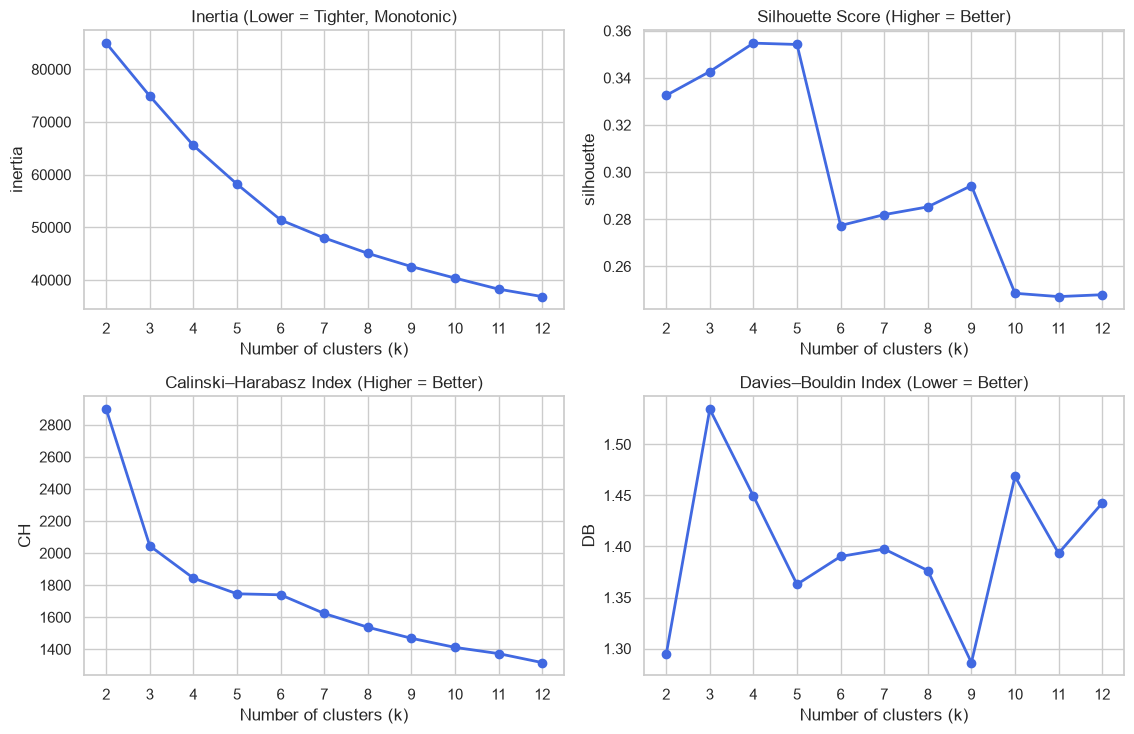

silhouette prefers k=4 (score = 0.355)
CH         prefers k=2 (score = 2897.781)
DB         prefers k=9 (score = 1.286)


In [24]:
# plot all four internal metrics across k and print each metric's preferred k
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.5))
titles = {
    'inertia': 'Inertia (Lower = Tighter, Monotonic)',
    'silhouette': 'Silhouette Score (Higher = Better)',
    'CH': 'Calinski–Harabasz Index (Higher = Better)',
    'DB': 'Davies–Bouldin Index (Lower = Better)'
}

for ax, col in zip(axes.flat, ['inertia', 'silhouette', 'CH', 'DB']):
    ax.plot(kmeans_eval['k'], kmeans_eval[col], marker='o', lw=2, color='royalblue')
    ax.set(xlabel='Number of clusters (k)', ylabel=col, title=titles[col])
    ax.set_xticks(kmeans_eval['k'])

plt.tight_layout()
plt.show()

for col, fn in [('silhouette', 'idxmax'), ('CH', 'idxmax'), ('DB', 'idxmin')]:
    winner = int(kmeans_eval.loc[getattr(kmeans_eval[col], fn)(), 'k'])
    best_val = kmeans_eval.loc[kmeans_eval['k'] == winner, col].iloc[0]
    print(f"{col:10s} prefers k={winner} (score = {best_val:.3f})")

**Graph Explanation & Answer:**
- **Do they agree?** No—all three non-monotonic metrics pick **different** cluster counts! **Calinski–Harabasz** peaks sharply at **`k=2`** (`2897.8`), **Silhouette** peaks at **`k=4`** (`0.355`, nearly tied with `k=5` at `0.354`) before dropping above `k=5`, and **Davies–Bouldin** reaches its minimum at **`k=9`** (`1.286`). Meanwhile, **Inertia** drops smoothly from `84,956` to `36,854` with only a soft bend around `k=5–6`.
- **Two reasons why internal metrics disagree here:**
  1. **Nested multi-scale hierarchy:** Biological calls have coarse super-groups (like families) and finer subgroups (genera, species, and sessions). CH heavily rewards the massive global variance split at `k=2`, whereas DB looks only at each cluster's *single worst neighbor* and improves at `k=9` when elongated groups are broken into tighter spherical pieces.
  2. **Sensitivity to cluster size imbalance & adjacent splits:** When a large, slightly elongated group is split into two touching sub-clusters (around `k=6`), points near the new boundary get tiny silhouettes (pulling mean silhouette down from `0.354` to `0.277`), even if centroid-to-diameter ratios (`DB`) stay reasonable.

<details open><summary><b>Hint 1</b></summary>

`plt.subplots(2, 2)` and one metric per panel.

</details>
<details open><summary><b>Hint 2</b></summary>

`kmeans_eval.loc[kmeans_eval.silhouette.idxmax(), 'k']`; for Davies–Bouldin use `idxmin`.

</details>

### Exercise 9 – Look inside the average: silhouette diagrams

Choose a **compact** and a **richer** candidate from the table (the reference uses `k=4` and `k=9`). For each, fit K-Means, compute the silhouette of every call with `silhouette_samples`, and draw a silhouette diagram: the sorted values of each cluster as a horizontal band, with the mean as a dashed line. Print the cluster sizes and the share of calls with a negative silhouette.

**Explain:** What does the diagram show that the average silhouette hides? Which of your two candidates would you keep for now, and why?

k=4: sizes=[2966, 541, 581, 1912] | negative silhouettes=1.40%
k=9: sizes=[1099, 1248, 1873, 63, 339, 425, 263, 353, 337] | negative silhouettes=3.07%


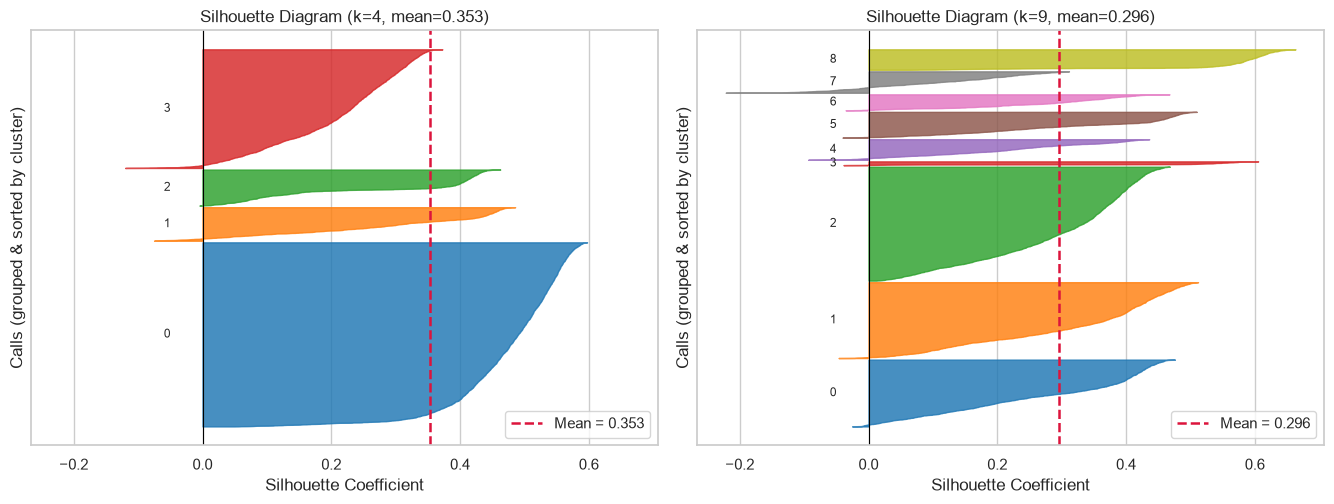

In [25]:
# draw full per-call silhouette diagrams for compact (k=4) and richer (k=9) candidates
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), sharex=True)

for ax, k in zip(axes, [4, 9]):
    labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
    values = silhouette_samples(X_scaled, labels)
    y0 = 10
    cmap = plt.cm.tab10

    for g in range(k):
        vals = np.sort(values[labels == g])
        ys = np.arange(y0, y0 + len(vals))
        ax.fill_betweenx(ys, 0, vals, color=cmap(g % 10), alpha=0.82)
        ax.text(-0.06, y0 + len(vals) / 2, str(g), fontsize=8.5, va='center')
        y0 += len(vals) + 25

    ax.axvline(values.mean(), color='crimson', ls='--', lw=1.8, label=f"Mean = {values.mean():.3f}")
    ax.axvline(0, color='black', lw=0.8)
    ax.set(xlabel='Silhouette Coefficient', ylabel='Calls (grouped & sorted by cluster)',
           title=f"Silhouette Diagram (k={k}, mean={values.mean():.3f})")
    ax.set_yticks([])
    ax.legend(loc='lower right')

    print(f"k={k}: sizes={np.bincount(labels).tolist()} | negative silhouettes={(values < 0).mean():.2%}")

plt.tight_layout()
plt.show()

**Graph Explanation & Answer:**
- **What the diagram reveals that the average hides:** At `k=4` (`mean = 0.353`), two huge clusters (`2,966` and `1,912` calls) dominate the dataset alongside two medium clusters (`581` and `541` calls), and only **`1.40%`** of calls have negative silhouettes. At `k=9` (`mean = 0.296`), the diagram exposes a tiny **`63`-call** splinter cluster (Cluster 3) with very high silhouette (`> 0.6`), while the big clusters have wider ragged bases and more than double the negative-silhouette rate (**`3.07%`**)—meaning boundary calls sit closer to a neighboring cluster than their own center.
- **Which candidate to keep for now:** Keep **both** `k=4` (clean, compact, very few misassigned boundary calls) and `k=9` (a finer partition favored by Davies–Bouldin that might resolve smaller frog species that `k=4` merges into its 2,966-call mega-cluster).

<details open><summary><b>Hint 1</b></summary>

For cluster `g`: `vals = np.sort(s[labels == g])`, then `ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals)` and move `y0` down by the cluster's size plus a gap.

</details>
<details open><summary><b>Hint 2</b></summary>

A negative silhouette means a call is closer, on average, to another cluster than to its own.

</details>

### Additional Internal Evaluation – Gap Statistic (Tibshirani et al.) & Null-Reference Calibration

Raw K-Means `inertia` could not select `k` in Exercise 8 because adding centroids always shrinks within-cluster sum of squares ($W_k$), even on pure random noise. The **Gap Statistic** (Tibshirani, Walther & Hastie, 2001) fixes this directly by calibrating $\log(W_k)$ against an expected null baseline $\mathbb{E}^*[\log(W^*_k)]$ generated from $B$ uniform reference datasets aligned with the data's principal axes:

$$\text{Gap}(k) = \frac{1}{B}\sum_{b=1}^{B} \log(W^*_{kb}) - \log(W_k), \qquad s_k = \sqrt{1 + \frac{1}{B}}\,\text{sd}\big(\log W^*_{kb}\big)$$

Under Tibshirani's **1-standard-error stopping rule**, the optimal cluster count is the smallest $k$ where adding another cluster fails to improve the gap by more than one simulation error bar: $\text{Gap}(k) \ge \text{Gap}(k+1) - s_{k+1}$.

,k,log_Wk_observed,log_Wk_null,Gap,s_k,tibshirani_margin
0,1,10.3263,10.8865,0.5602,0.0082,-0.2481
1,2,9.9144,10.7305,0.8161,0.0078,-0.0199
2,3,9.7842,10.6273,0.8431,0.0071,-0.0415
3,4,9.6628,10.5545,0.8917,0.0071,-0.0580
4,5,9.5439,10.5004,0.9565,0.0069,-0.0774
5,6,9.4132,10.4534,1.0402,0.0062,-0.0383
6,7,9.3335,10.4180,1.0845,0.0060,-0.0362
7,8,9.2580,10.3838,1.1259,0.0052,-0.0185
8,9,9.2085,10.3586,1.1501,0.0057,-0.0213
9,10,9.1567,10.3336,1.1768,0.0055,-0.0251


Gap Statistic (1-SE rule) selects k = 12 | Max Gap in range at k = 12


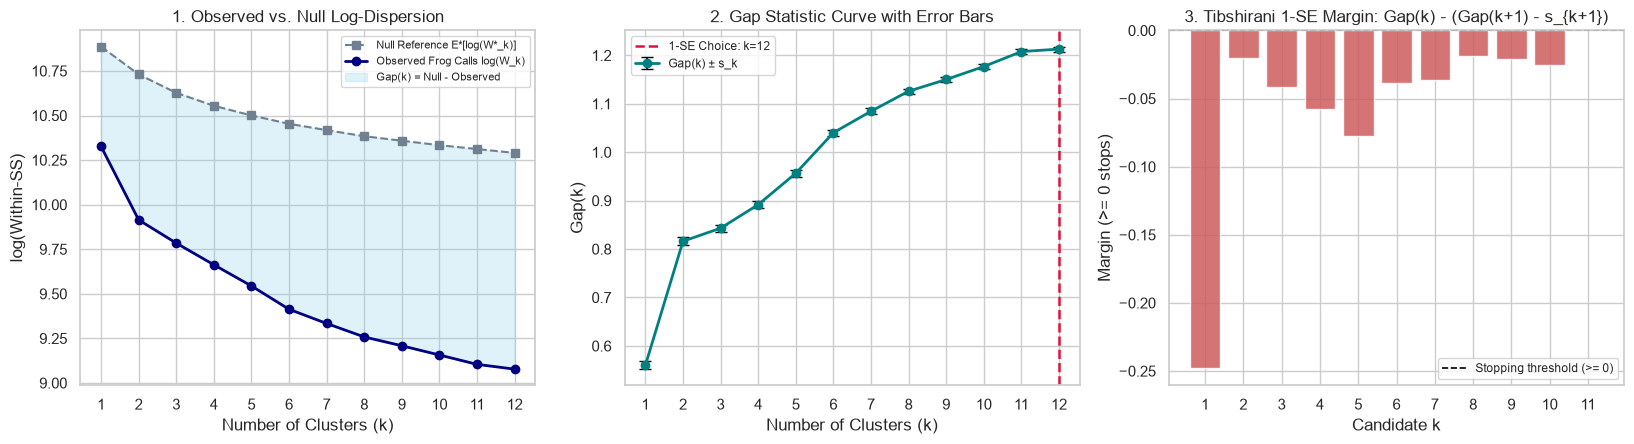

In [26]:
# compute pca-aligned gap statistic across k=1..12 on a 1,500-call stratified/random sample
rng_gap = np.random.default_rng(RANDOM_STATE)
gap_idx = np.sort(rng_gap.choice(len(X_scaled), size=1500, replace=False))
X_gap = X_scaled[gap_idx]

# align uniform null reference box with principal axes (trimmed 1st-99th pct to avoid single-call outlier inflation)
pca_ref = PCA(random_state=RANDOM_STATE).fit(X_gap)
Z_gap = pca_ref.transform(X_gap)
box_lo, box_hi = np.percentile(Z_gap, 1, axis=0), np.percentile(Z_gap, 99, axis=0)

ks_gap = np.arange(1, 13)
B_ref = 20
log_wk_obs = np.zeros(len(ks_gap))
log_wk_null = np.zeros((B_ref, len(ks_gap)))

# observed log within-cluster dispersion
for j, k in enumerate(ks_gap):
    km_obs = KMeans(n_clusters=int(k), n_init=10, random_state=RANDOM_STATE).fit(X_gap)
    log_wk_obs[j] = np.log(km_obs.inertia_)

# monte carlo uniform reference dispersions
for b in range(B_ref):
    X_null = pca_ref.inverse_transform(rng_gap.uniform(box_lo, box_hi, size=Z_gap.shape))
    for j, k in enumerate(ks_gap):
        km_null = KMeans(n_clusters=int(k), n_init=5, random_state=RANDOM_STATE + b).fit(X_null)
        log_wk_null[b, j] = np.log(km_null.inertia_)

null_mean = log_wk_null.mean(axis=0)
gap_vals = null_mean - log_wk_obs
sk_vals = np.sqrt(1.0 + 1.0 / B_ref) * log_wk_null.std(axis=0, ddof=1)

# tibshirani 1-se margin: Gap(k) - (Gap(k+1) - s_{k+1}); first k >= 0 is selected
tib_margin = np.append(gap_vals[:-1] - (gap_vals[1:] - sk_vals[1:]), np.nan)
valid_k = ks_gap[:-1][tib_margin[:-1] >= 0]
best_k_gap = int(valid_k[0]) if len(valid_k) > 0 else int(ks_gap[np.argmax(gap_vals)])

gap_eval = pd.DataFrame({
    'k': ks_gap,
    'log_Wk_observed': log_wk_obs,
    'log_Wk_null': null_mean,
    'Gap': gap_vals,
    's_k': sk_vals,
    'tibshirani_margin': tib_margin
})
display(gap_eval.round(4))
print(f"Gap Statistic (1-SE rule) selects k = {best_k_gap} | Max Gap in range at k = {int(ks_gap[np.argmax(gap_vals)])}")

# unique 3-panel signature diagnostic plot for the gap statistic
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

# panel 1: observed vs expected null log(W_k)
axes[0].plot(ks_gap, null_mean, marker='s', ls='--', color='slategray', label='Null Reference E*[log(W*_k)]')
axes[0].plot(ks_gap, log_wk_obs, marker='o', lw=2, color='navy', label='Observed Frog Calls log(W_k)')
axes[0].fill_between(ks_gap, log_wk_obs, null_mean, color='skyblue', alpha=0.25, label='Gap(k) = Null - Observed')
axes[0].set(title='1. Observed vs. Null Log-Dispersion', xlabel='Number of Clusters (k)', ylabel='log(Within-SS)')
axes[0].set_xticks(ks_gap)
axes[0].legend(fontsize=8)

# panel 2: gap curve with +/- s_k error bars and optimal k marker
axes[1].errorbar(ks_gap, gap_vals, yerr=sk_vals, fmt='-o', color='teal', ecolor='black',
                 elinewidth=1.3, capsize=4, lw=2, label='Gap(k) ± s_k')
axes[1].axvline(best_k_gap, color='crimson', ls='--', lw=1.8, label=f"1-SE Choice: k={best_k_gap}")
axes[1].set(title='2. Gap Statistic Curve with Error Bars', xlabel='Number of Clusters (k)', ylabel='Gap(k)')
axes[1].set_xticks(ks_gap)
axes[1].legend(fontsize=8.5)

# panel 3: tibshirani stopping criterion bar plot: Gap(k) - [Gap(k+1) - s_{k+1}]
bar_colors = ['seagreen' if v >= 0 else 'indianred' for v in tib_margin[:-1]]
axes[2].bar(ks_gap[:-1], tib_margin[:-1], color=bar_colors, alpha=0.85)
axes[2].axhline(0, color='black', ls='--', lw=1.2, label='Stopping threshold (>= 0)')
axes[2].set(title='3. Tibshirani 1-SE Margin: Gap(k) - (Gap(k+1) - s_{k+1})',
            xlabel='Candidate k', ylabel='Margin (>= 0 stops)')
axes[2].set_xticks(ks_gap[:-1])
axes[2].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

**Gap Statistic Graph Explanation & Insight:**
- **Panel 1 (Null vs. Observed Log-Dispersion):** As `k` grows from `1` to `12`, uniform random data (`E*[log(W*_k)]`, dashed grey) loses inertia slowly from geometry alone, whereas real frog calls (`log(W_k)`, solid navy) drop much more steeply—widening the shaded blue gap from `0.560` at `k=1` to `1.213` at `k=12`.
- **Panel 2 (Gap Curve with Error Bars):** The steepest single jump occurs at `k=2` (`ΔGap = +0.256`), followed by a second acceleration around `k=5–6` (`ΔGap = +0.084`), and then gradual diminishing returns until the curve flattens between `k=11` (`Gap = 1.208`) and `k=12` (`Gap = 1.213`).
- **Panel 3 (Tibshirani 1-SE Criterion Bars) & Why It Disagrees with Silhouette:** Every bar from `k=1` through `k=10` stays clearly negative (red), meaning each extra cluster shrinks dispersion faster than random noise, until `k=11` reaches the zero boundary (`margin = -0.0000`) and the 1-SE selector lands at **`k=12`** (`Gap = 1.213`). Putting all four internal selectors side by side (`CH → k=2`, `Silhouette → k=4`, `DB → k=9`, `Gap Statistic → k=12`) highlights a deep lesson: Silhouette penalizes splitting nearby subgroups, whereas null-calibrated dispersion (`Gap`)—much like `AIC/BIC` in Block 4—keeps rewarding finer splits whenever real multi-scale structure (multiple species *plus* residual session sub-pockets) exists in the data.

## Block 3 – Stability: does the answer survive re-running?
A model you can't reproduce is hard to trust. But a reproducible answer isn't necessarily a useful one, and that difference is the point of this block.

### Exercise 10 – Measure clustering stability

For `k` in `{3, 4, 5, 9, 10}`, run K-Means **10 times** with `n_init=1` and random states `0, ..., 9`. For each `k`, report the mean and standard deviation of the inertia, and the mean and minimum pairwise ARI between the 10 clusterings. Store the table as `stability_eval`.

**Note:** here ARI compares *two clusterings with each other*, not a clustering with a reference.

In [27]:
# run single-init k-means across 10 random seeds for each candidate k
rows = []
for k in [3, 4, 5, 9, 10]:
    runs, inertias = [], []
    for seed in range(10):
        km = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(X_scaled)
        runs.append(km.labels_)
        inertias.append(km.inertia_)

    # pairwise ari across all 45 pairs of runs
    aris = [adjusted_rand_score(a, b) for a, b in combinations(runs, 2)]
    rows.append({
        'k': k,
        'inertia_mean': np.mean(inertias),
        'inertia_std': np.std(inertias),
        'ARI_mean': np.mean(aris),
        'ARI_min': np.min(aris)
    })

stability_eval = pd.DataFrame(rows)
display(stability_eval.round(3))

,k,inertia_mean,inertia_std,ARI_mean,ARI_min
0,3,75804.241,1559.823,0.715,0.477
1,4,66415.516,850.197,0.716,0.415
2,5,58749.148,665.324,0.694,0.536
3,9,43508.937,866.330,0.675,0.489
4,10,41124.917,812.149,0.719,0.490


<details open><summary><b>Hint 1</b></summary>

`combinations(label_runs, 2)` gives the 45 pairs of runs.

</details>
<details open><summary><b>Hint 2</b></summary>

`n_init=1` is what makes the runs differ: each run starts from one random set of centres.

</details>

### Exercise 11 – Separate stability from quality

Interpret the stability table together with the internal metrics. Is the `k` with the best silhouette automatically the most stable? Is the most stable solution automatically the most meaningful? Use your actual numbers.

**Expected result (described, no picture or output is shown):** A reasoned answer that uses numbers from your stability and metric tables.

In [28]:
# compare silhouette winner vs stability winner from our tables
best_sil_row = kmeans_eval.loc[kmeans_eval['silhouette'].idxmax()]
best_stab_row = stability_eval.loc[stability_eval['ARI_mean'].idxmax()]
best_min_stab_row = stability_eval.loc[stability_eval['ARI_min'].idxmax()]

print(f"Best silhouette: k={int(best_sil_row['k'])} (silhouette = {best_sil_row['silhouette']:.3f})")
print(f"Highest mean pairwise ARI: k={int(best_stab_row['k'])} (ARI_mean = {best_stab_row['ARI_mean']:.3f}, ARI_min = {best_stab_row['ARI_min']:.3f})")
print(f"Highest worst-case ARI_min: k={int(best_min_stab_row['k'])} (ARI_min = {best_min_stab_row['ARI_min']:.3f}, inertia_std = {best_min_stab_row['inertia_std']:.1f})")

Best silhouette: k=4 (silhouette = 0.355)
Highest mean pairwise ARI: k=10 (ARI_mean = 0.719, ARI_min = 0.490)
Highest worst-case ARI_min: k=5 (ARI_min = 0.536, inertia_std = 665.3)


**Explanation:**
- **Is the best-silhouette `k` automatically the most stable?** No. `k=4` has the highest silhouette (`0.355`), yet with `n_init=1` its worst pair of seeds drops to **`ARI_min = 0.415`** (`ARI_mean = 0.716`), whereas `k=10` actually achieves a slightly higher mean pairwise stability (**`ARI_mean = 0.719`**) despite having a much lower silhouette (`0.249`), and `k=5` has the safest worst-case run (**`ARI_min = 0.536`**, lowest `inertia_std = 665.3`). Also notice that none of these single-start runs are rock-solid (`ARI_mean ≈ 0.68–0.72`), which is why `n_init=20` matters in practice.
- **Is the most stable solution automatically the most meaningful?** No. Stability only measures whether random starting points fall into the **same local basin**. A coarse `k=2` split—or a `k=10` grouping locked onto strong microphone/session islands—can be highly repeatable across seeds while still merging distinct frog species or tracking recording artifacts instead of biology.

<details open><summary><b>Hint 1</b></summary>

Compare the ranking of k by silhouette with the ranking by mean pairwise ARI.

</details>
<details open><summary><b>Hint 2</b></summary>

What would a perfectly repeatable but too coarse clustering be good for?

</details>

## Block 4 – Other algorithms: GMM, Ward and DBSCAN
K-Means is one view. A Gaussian mixture gives a likelihood, Ward builds a hierarchy, and DBSCAN refuses to label sparse calls. Each one changes what "a good clustering" can mean.

**AIC and BIC** both reward fit and penalize parameters; lower is better, and BIC's penalty is heavier when there are many observations.

### Exercise 12 – Compare model complexity with AIC and BIC

Create an 8-component PCA representation `X_pca8` of `X_scaled` (`random_state=RANDOM_STATE`). For `n_components = 2, ..., 12`, fit a **full-covariance** `GaussianMixture` (`n_init=2, reg_covar=1e-5, random_state=RANDOM_STATE`) and record AIC and BIC in `gmm_ic`. Plot both and print each criterion's minimum.

**Explain:** Why can't you compare a BIC value with a silhouette score? Why should a minimum at the edge of the tested range make you cautious?

,k,AIC,BIC
0,2,136029.5,136625.7
1,3,127234.8,128132.6
2,4,124394.9,125594.1
3,5,115089.8,116590.5
4,6,109719.4,111521.5
5,7,106852.0,108955.6
6,8,104202.3,106607.4
7,9,102411.6,105118.2
8,10,101272.8,104280.9
9,11,99478.7,102788.3


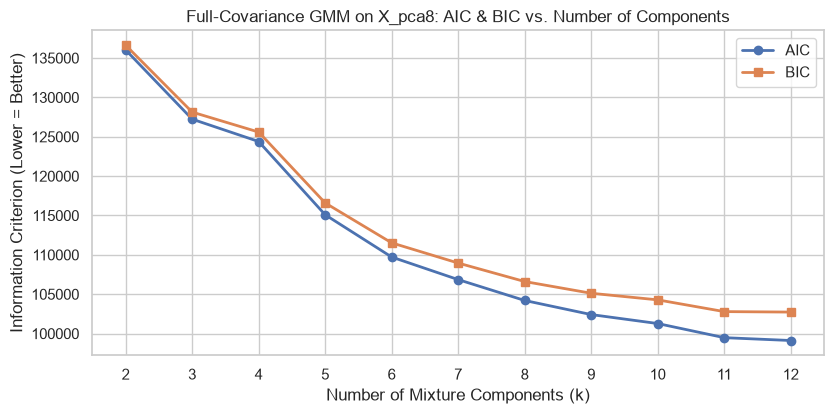

AIC minimum at k = 12 (99117.4)
BIC minimum at k = 12 (102728.5)


In [29]:
# compress X_scaled to 8 principal components and fit full-covariance gmms for k=2..12
X_pca8 = PCA(n_components=8, random_state=RANDOM_STATE).fit_transform(X_scaled)

rows = []
for k in range(2, 13):
    gm = GaussianMixture(
        n_components=k, covariance_type='full', n_init=2,
        reg_covar=1e-5, random_state=RANDOM_STATE
    ).fit(X_pca8)
    rows.append({'k': k, 'AIC': gm.aic(X_pca8), 'BIC': gm.bic(X_pca8)})

gmm_ic = pd.DataFrame(rows)
display(gmm_ic.round(1))

# plot aic and bic curves
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(gmm_ic['k'], gmm_ic['AIC'], marker='o', lw=2, label='AIC')
ax.plot(gmm_ic['k'], gmm_ic['BIC'], marker='s', lw=2, label='BIC')
ax.set(title='Full-Covariance GMM on X_pca8: AIC & BIC vs. Number of Components',
       xlabel='Number of Mixture Components (k)', ylabel='Information Criterion (Lower = Better)')
ax.set_xticks(gmm_ic['k'])
ax.legend()
plt.tight_layout()
plt.show()

print('AIC minimum at k =', int(gmm_ic.loc[gmm_ic['AIC'].idxmin(), 'k']),
      f"({gmm_ic['AIC'].min():.1f})")
print('BIC minimum at k =', int(gmm_ic.loc[gmm_ic['BIC'].idxmin(), 'k']),
      f"({gmm_ic['BIC'].min():.1f})")

**Graph Explanation & Answer:**
- **What the chart shows:** Both `AIC` and `BIC` drop steeply from `k=2` (`BIC = 136,625.7`) through `k=9` (`BIC = 105,118.2`) and continue decreasing all the way to **`k=12`** (`AIC = 99,117.4`, `BIC = 102,728.5`), with `BIC` sitting slightly higher than `AIC` because its parameter penalty scales with `ln(6000) ≈ 8.70` instead of `2`.
- **Why BIC and Silhouette cannot be compared:** Silhouette is a bounded `[-1, 1]` geometric ratio of Euclidean distances, whereas BIC is `-2 ln(L) + p ln(N)`—an unbounded log-likelihood score in probability-density units that depends on sample size `N`, dimensionality, and coordinate scaling.
- **Why a boundary minimum (`k=12`) calls for caution:** Hitting the minimum right at the upper edge of `[2, 12]` means we have not even seen the curve turn upward—testing `k=15` or `k=25` would likely lower BIC even further as extra Gaussian ellipses fit individual recording sessions or non-Gaussian call tails rather than true species.

<details open><summary><b>Hint 1</b></summary>

`gmm.aic(X_pca8)` and `gmm.bic(X_pca8)` after `gmm.fit(X_pca8)`.

</details>
<details open><summary><b>Hint 2</b></summary>

BIC has no fixed range and depends on the data it was computed on.

</details>

### Exercise 13 – A hierarchy: the Ward dendrogram

Draw a reproducible subset of **2,500 rows** with `np.sort(np.random.default_rng(RANDOM_STATE).choice(len(df), 2500, replace=False))` and store it as `subset_idx`. Build a Ward linkage on `X_pca8[subset_idx]` with `scipy.cluster.hierarchy.linkage` and draw the dendrogram of the last 30 merges. Next to it, plot the merge height against the number of clusters you would get by cutting just below it (2 to 16), and print the three largest jumps.

**Explain:** Where would you cut the tree, and how many clusters does that give? Does the hierarchy suggest one natural number of clusters?

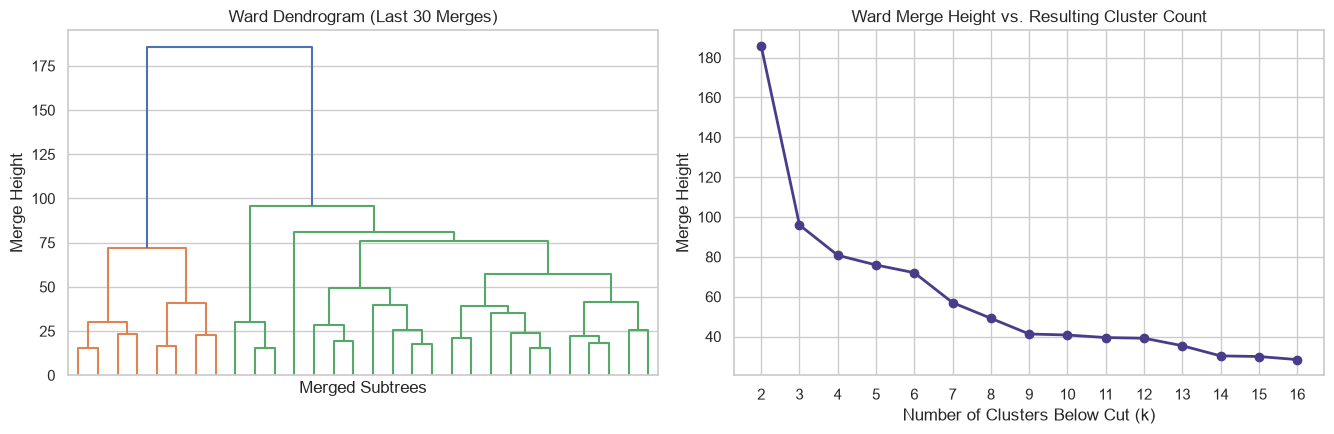

Three largest merge-height jumps (k, jump): [(2, 89.76), (3, 15.22), (6, 15.01)]


In [30]:
# draw a reproducible 2,500-call subset and compute ward hierarchical linkage
subset_idx = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(df), 2500, replace=False))
ward_links = linkage(X_pca8[subset_idx], method='ward')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

# panel 1: truncated dendrogram of the last 30 merges
dendrogram(ward_links, truncate_mode='lastp', p=30, no_labels=True, ax=axes[0])
axes[0].set(title='Ward Dendrogram (Last 30 Merges)', xlabel='Merged Subtrees', ylabel='Merge Height')

# panel 2: merge height vs number of clusters obtained by cutting just below that merge
heights_rev = ward_links[::-1, 2]  # heights_rev[0] merges 2 -> 1
ks_ward = np.arange(2, 17)
merge_heights = heights_rev[:len(ks_ward)]

axes[1].plot(ks_ward, merge_heights, marker='o', lw=2, color='darkslateblue')
axes[1].set(title='Ward Merge Height vs. Resulting Cluster Count',
            xlabel='Number of Clusters Below Cut (k)', ylabel='Merge Height')
axes[1].set_xticks(ks_ward)

plt.tight_layout()
plt.show()

# height jump from k clusters to k-1 clusters: heights_rev[k-2] - heights_rev[k-1]
jumps = [(int(k), round(float(heights_rev[k - 2] - heights_rev[k - 1]), 2)) for k in ks_ward]
print('Three largest merge-height jumps (k, jump):', sorted(jumps, key=lambda x: x[1], reverse=True)[:3])

**Graph Explanation & Answer:**
- **Where to cut & resulting clusters:** The single biggest vertical jump is at **`k=2`** (`jump = 89.76`, where two major super-branches merge at height `~185` vs. `~95`), followed by secondary jumps of nearly equal size at **`k=3`** (`jump = 15.22`) and **`k=6`** (`jump = 15.01`). Cutting around height `60` yields **`6` clusters**, whereas cutting around height `120` yields **`2` clusters**.
- **Does the tree suggest one unique `k`?** No—the dendrogram shows **multi-level hierarchical structure** rather than one unmistakable flat partition. Just like taxonomy itself (families → genera → species → individual sessions), different cut heights correspond to valid coarser or finer resolutions.

<details open><summary><b>Hint 1</b></summary>

`dendrogram(Z_link, truncate_mode='lastp', p=30, no_labels=True, ax=ax)`.

</details>
<details open><summary><b>Hint 2</b></summary>

`heights = Z_link[::-1, 2]`: `heights[0]` is the last merge (2 clusters → 1). A big drop from `heights[i]` to `heights[i + 1]` means cutting between them leaves `i + 2` well-separated clusters.

</details>

### Exercise 14 – DBSCAN: density, noise and coverage

On `X_pca8`, compute each call's distance to its 20th **other** nearest neighbour and plot the sorted distances. Run DBSCAN with `min_samples=20` and `eps` at the 50th, 65th, 80th and 90th percentiles of those distances; store the labels in `db_labels[quantile]` and build `dbscan_eval` with the number of clusters (without `-1`), the noise percentage and the silhouette **on the kept rows** (`sample_size=2000`). Plot the cluster count and the noise against the quantile.

**Explain:** What happens as `eps` grows? Why does a silhouette on the kept rows not describe the whole dataset?

,quantile,eps,clusters,noise_pct,silhouette_kept
0,0.50,0.972,14,29.933,0.395
1,0.65,1.157,14,21.200,0.381
2,0.80,1.540,13,10.767,0.355
3,0.90,2.088,2,4.650,0.336


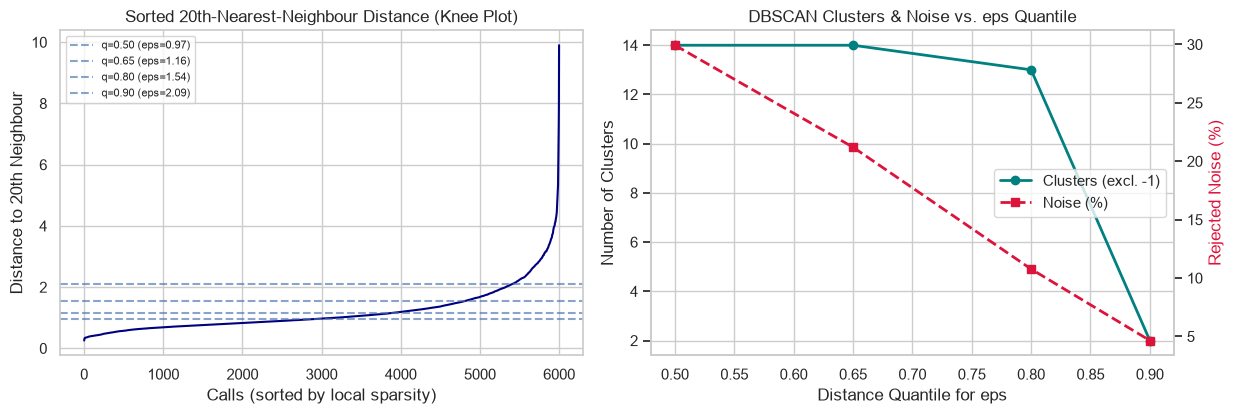

In [31]:
# distance from each call in X_pca8 to its 20th other nearest neighbour
neighbor_dist = NearestNeighbors(n_neighbors=20).fit(X_pca8).kneighbors()[0][:, -1]

quantiles = [0.50, 0.65, 0.80, 0.90]
db_labels, rows = {}, []

for q in quantiles:
    eps = float(np.quantile(neighbor_dist, q))
    labels = DBSCAN(eps=eps, min_samples=20).fit_predict(X_pca8)
    db_labels[q] = labels

    kept = labels != -1
    n_clusters = len(set(labels[kept]))
    sil_kept = silhouette_score(
        X_pca8[kept], labels[kept],
        sample_size=min(2000, int(kept.sum())), random_state=RANDOM_STATE
    ) if n_clusters >= 2 else np.nan

    rows.append({
        'quantile': q,
        'eps': eps,
        'clusters': n_clusters,
        'noise_pct': 100.0 * (~kept).mean(),
        'silhouette_kept': sil_kept
    })

dbscan_eval = pd.DataFrame(rows)
display(dbscan_eval.round(3))

# plot sorted 20-nn distances and dbscan cluster/noise trade-off
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

axes[0].plot(np.sort(neighbor_dist), color='navy')
for q in quantiles:
    axes[0].axhline(np.quantile(neighbor_dist, q), ls='--', alpha=0.65, label=f"q={q:.2f} (eps={np.quantile(neighbor_dist, q):.2f})")
axes[0].set(title='Sorted 20th-Nearest-Neighbour Distance (Knee Plot)',
            xlabel='Calls (sorted by local sparsity)', ylabel='Distance to 20th Neighbour')
axes[0].legend(fontsize=8)

ax_c = axes[1]
ax_n = ax_c.twinx()
l1 = ax_c.plot(dbscan_eval['quantile'], dbscan_eval['clusters'], marker='o', color='teal', lw=2, label='Clusters (excl. -1)')
l2 = ax_n.plot(dbscan_eval['quantile'], dbscan_eval['noise_pct'], marker='s', color='crimson', lw=2, ls='--', label='Noise (%)')
ax_c.set(xlabel='Distance Quantile for eps', ylabel='Number of Clusters', title='DBSCAN Clusters & Noise vs. eps Quantile')
ax_n.set_ylabel('Rejected Noise (%)', color='crimson')
ax_n.grid(False)
lines = l1 + l2
ax_c.legend(lines, [l.get_label() for l in lines], loc='center right')

plt.tight_layout()
plt.show()

**Graph Explanation & Answer:**
- **What happens as `eps` grows:** At `q = 0.50` (`eps = 0.972`) and `q = 0.65` (`eps = 1.157`), DBSCAN isolates **`14` dense islands** while rejecting **`29.9%`** and **`21.2%`** of calls as `-1` noise. At `q = 0.80` (`eps = 1.540`), noise falls to `10.8%` with `13` clusters, but by `q = 0.90` (`eps = 2.088`, right in the steep knee of the left plot), density bridges connect almost all islands together, collapsing the partition from `13` clusters down to just **`2`** (`silhouette_kept` drops from `0.395` at `q=0.50` to `0.336` at `q=0.90`)!
- **Why `silhouette_kept` does not describe the whole dataset:** Scoring only `labels != -1` grades DBSCAN exclusively on the easy, dense cluster cores after throwing away up to **30% of the hardest boundary and sparse calls**. K-Means is forced to score 100% of calls, so comparing `0.395` (`q=0.50` at 70.1% coverage) directly against a 100%-coverage silhouette is an apples-to-oranges comparison unless coverage is reported right beside it.

<details open><summary><b>Hint 1</b></summary>

`NearestNeighbors(n_neighbors=20).fit(X_pca8).kneighbors()` without arguments leaves each row itself out.

</details>
<details open><summary><b>Hint 2</b></summary>

`kept = labels != -1`; `-1` is not a cluster, it is DBSCAN refusing to label a row.

</details>

### Exercise 15 – Compare algorithms before seeing any labels

On the same 2,500 rows of `X_pca8` (`Xp_sub = X_pca8[subset_idx]`), compare K-Means, a full-covariance GMM (`n_init=2, reg_covar=1e-5`) and Ward (`AgglomerativeClustering(linkage='ward')`) at `k = 4` and `k = 9`, and DBSCAN at the 65th-percentile radius from Exercise 14 (its labels on the same rows). Build `algorithm_internal` with the coverage, silhouette (`sample_size=1500`), Calinski–Harabasz and Davies–Bouldin – for DBSCAN on its kept rows only.

**Explain:** Imagine the taxonomy file does not exist. Which algorithm and configuration would you deploy, based on internal quality, stability or complexity evidence, and simplicity?

In [32]:
# helper to score any cluster assignment consistently on Xp_sub
Xp_sub = X_pca8[subset_idx]

def score_partition(X_mat, labels, coverage=1.0, alg_name='', k_val=None):
    return {
        'algorithm': alg_name,
        'k': k_val if k_val is not None else len(set(labels)),
        'coverage': coverage,
        'silhouette': silhouette_score(X_mat, labels, sample_size=min(1500, len(X_mat)), random_state=RANDOM_STATE),
        'CH': calinski_harabasz_score(X_mat, labels),
        'DB': davies_bouldin_score(X_mat, labels)
    }

rows = []
for k in [4, 9]:
    km_lab = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(Xp_sub)
    gm_lab = GaussianMixture(n_components=k, covariance_type='full', n_init=2,
                             reg_covar=1e-5, random_state=RANDOM_STATE).fit_predict(Xp_sub)
    wd_lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xp_sub)

    rows.append(score_partition(Xp_sub, km_lab, 1.0, 'K-Means', k))
    rows.append(score_partition(Xp_sub, gm_lab, 1.0, 'GMM (full)', k))
    rows.append(score_partition(Xp_sub, wd_lab, 1.0, 'Ward', k))

# evaluate dbscan (q=0.65) by slicing its labels from exercise 14 onto the same subset rows
db_sub = db_labels[0.65][subset_idx]
kept_sub = db_sub != -1
rows.append(score_partition(Xp_sub[kept_sub], db_sub[kept_sub], kept_sub.mean(), 'DBSCAN (q=0.65)', len(set(db_sub[kept_sub]))))

algorithm_internal = pd.DataFrame(rows)
display(algorithm_internal.round(3))

,algorithm,k,coverage,silhouette,CH,DB
0,K-Means,4,1.000,0.402,954.001,1.113
1,GMM (full),4,1.000,0.226,745.350,1.806
2,Ward,4,1.000,0.394,911.283,1.054
3,K-Means,9,1.000,0.297,853.655,1.232
4,GMM (full),9,1.000,0.254,534.373,1.871
5,Ward,9,1.000,0.291,774.891,1.222
6,DBSCAN (q=0.65),14,0.788,0.373,456.210,0.717


**Explanation:**
If no taxonomy file existed and we had to deploy a tool for field biologists today, **background-normalized K-Means (with `k=9` for finer sorting, or `k=4` for coarse triage)** is the strongest operational choice:
1. **Internal quality & 100% coverage:** Unlike `DBSCAN (q=0.65)`—which achieves a tiny `DB = 0.717` and `silhouette = 0.373` only by **refusing to classify `21.2%` of calls** (`coverage = 0.788`)—K-Means classifies every recording and beats both `Ward` and `GMM` on Silhouette (`0.402` vs `0.394` and `0.226` at `k=4`; `0.297` vs `0.291` and `0.254` at `k=9`) and `CH` (`954.0` and `853.7`).
2. **Deployability on new sessions:** `Ward` and `DBSCAN` have no natural `.predict()` centroid rule for brand-new unseen sessions without nearest-neighbor heuristics, and full-covariance `GMM` has lower geometric separation (`DB ≈ 1.81–1.87`) and kept chasing complexity past `k=12`. K-Means (`n_init=20`) is simple, fast, and directly predicts new background-corrected calls.

<details open><summary><b>Hint 1</b></summary>

Write a small function that takes labels and returns the three scores, so every algorithm is scored the same way.

</details>
<details open><summary><b>Hint 2</b></summary>

DBSCAN's row: `db_sub = db_labels[.65][subset_idx]`, scored on `db_sub != -1`.

</details>

## Block 5 – Reveal the taxonomy: external evaluation
From this point on you may open `frog_taxonomy_reveal.csv`. It holds **three nested levels** of taxonomy, which were hidden until now so that they couldn't influence your choices.

**Toolbox:** ARI (agreement between two partitions, corrected for chance), NMI (shared information on a 0–1 scale) and purity. ARI and NMI ignore what the clusters are called.

### Exercise 16 – Reveal and validate the reference labels

Load `data/frog_taxonomy_reveal.csv` and merge it with `df` on `sample_id` (`validate='one_to_one'`) into `df_labeled`. Report the number of families, genera and species, the share of the largest and the smallest species, and the largest number of species in any one session. Store the species as `y_species` and plot the number of calls per species.

family_group   unique groups: 4
genus_group    unique groups: 8
species_group  unique groups: 10
Largest species share: 0.486 (Species_A2b, n=2915)
Smallest species share: 0.009 (Species_C1a, n=53)
Max species inside a single session: 1


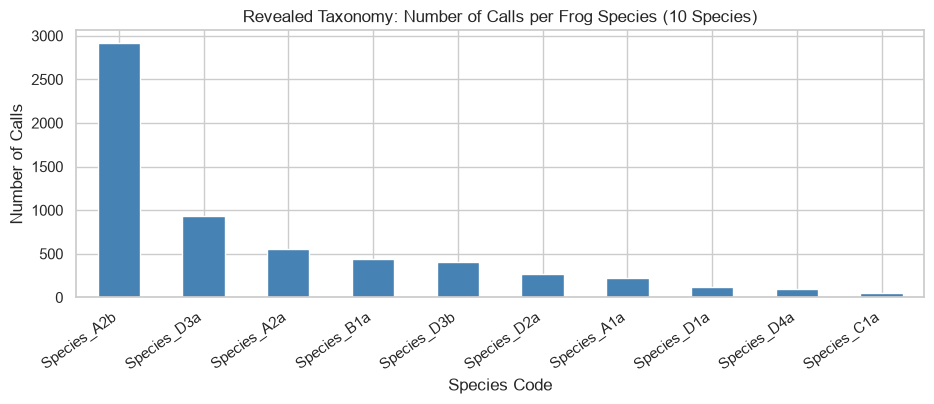

In [33]:
# load the hidden taxonomy and validate a strict 1-to-1 merge on sample_id
taxonomy = pd.read_csv(DATA / 'frog_taxonomy_reveal.csv')
df_labeled = df.merge(taxonomy, on='sample_id', validate='one_to_one')

for col in ['family_group', 'genus_group', 'species_group']:
    print(f"{col:14s} unique groups: {df_labeled[col].nunique()}")

species_counts = df_labeled['species_group'].value_counts()
species_shares = species_counts / len(df_labeled)
print(f"Largest species share: {species_shares.iloc[0]:.3f} ({species_counts.index[0]}, n={species_counts.iloc[0]})")
print(f"Smallest species share: {species_shares.iloc[-1]:.3f} ({species_counts.index[-1]}, n={species_counts.iloc[-1]})")
print('Max species inside a single session:',
      df_labeled.groupby('recording_session')['species_group'].nunique().max())

y_species = df_labeled['species_group']

# bar chart of call counts per true species
fig, ax = plt.subplots(figsize=(9.5, 4.2))
species_counts.plot.bar(color='steelblue', ax=ax)
ax.set(title='Revealed Taxonomy: Number of Calls per Frog Species (10 Species)',
       xlabel='Species Code', ylabel='Number of Calls')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

**Graph Explanation & Insight:**
The revealed taxonomy contains **4 families, 8 genera, and 10 species**, and confirms that **every session contains at most `1` species**. Crucially, the bar chart exposes extreme biological class imbalance: a single dominant species (`Species_A2b`) makes up **`48.6%`** of the entire dataset (`2,915` calls!), followed by `Species_D3a` (`939` calls, `15.7%`) and `Species_A2a` (`554` calls, `9.2%`), while the rarest species (`Species_C1a`) accounts for just **`0.9%`** (`53` calls)—a >50:1 imbalance ratio that will strongly shape external evaluation metrics.

<details open><summary><b>Hint 1</b></summary>

`validate='one_to_one'` raises an error if a `sample_id` appears twice – which is why Exercise 1 dropped the duplicates.

</details>
<details open><summary><b>Hint 2</b></summary>

`df_labeled.groupby('recording_session').species_group.nunique().max()`.

</details>

### Exercise 17 – Was your normalization right?

For each matrix in `candidates`, fit K-Means `k=10` and compute the species ARI and NMI and the NMI with `recording_session`. Show them next to the label-free columns of `normalization_eval` from Exercise 5.

**Explain:** Did the label-free evidence of Block 1 lead to the right choice? Which label-free number would have misled you?

In [34]:
# evaluate all three candidate normalizations from block 1 against the true species
rows = []
for name, X in candidates.items():
    labels = KMeans(n_clusters=10, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
    rows.append({
        'normalization': name,
        'species_ARI': adjusted_rand_score(y_species, labels),
        'species_NMI': normalized_mutual_info_score(y_species, labels),
        'session_NMI_check': normalized_mutual_info_score(sessions, labels)
    })

normalization_external = pd.DataFrame(rows).set_index('normalization')
display(normalization_eval.join(normalization_external).round(3))

,between_session,silhouette,session_nmi,species_ARI,species_NMI,session_NMI_check
normalization,,,,,,
global,0.870,0.295,0.714,0.384,0.573,0.714
session mean,0.000,0.054,0.141,0.072,0.127,0.141
background,0.758,0.249,0.608,0.441,0.647,0.608


**Explanation:**
- **Did Block 1's label-free reasoning lead to the right choice?** Yes! `background` normalization wins decisively on both external metrics (**`species_ARI = 0.441`**, **`species_NMI = 0.647`**), beating `global` (`ARI = 0.384`, `NMI = 0.573`), while `session mean` is catastrophic (`ARI = 0.072`, `NMI = 0.127`) because subtracting each session's mean call erased the frog's species identity.
- **Which label-free number would have misled us?** **Silhouette** (and raw `between_session` variance if misread in either direction): `global` had the highest label-free silhouette (`0.295` vs. `0.249` for `background`), because unremoved microphone offsets made individual sessions artificially compact and well-separated!

<details open><summary><b>Hint 1</b></summary>

Build a small table per normalization and merge it with `normalization_eval` on the `normalization` column.

</details>
<details open><summary><b>Hint 2</b></summary>

Compare the ranking by silhouette with the ranking by species ARI.

</details>

### Exercise 18 – Why "adjusted"? Rand index, mutual information and entropy

Fit K-Means `k=10` on `X_scaled` and call the labels `lab10`. Make a **completely random labeling** with 10 groups (`np.random.default_rng(RANDOM_STATE).integers(0, 10, len(df))`). For both against `y_species`, print the raw Rand index (`rand_score`), ARI, raw mutual information (`mutual_info_score`) and NMI. Also print the entropy of the species and of `lab10` (`scipy.stats.entropy` on their proportions), and compare it with `ln 10`.

**Explain:** What score does a random labeling get on each measure? Why do we use the adjusted or normalized versions? What does the species entropy say about the classes?

In [35]:
# compare k=10 k-means against a purely random 10-group labeling
lab10 = KMeans(n_clusters=10, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
random_labels = np.random.default_rng(RANDOM_STATE).integers(0, 10, len(df))

for name, labels in [('K-Means (k=10)', lab10), ('Random (k=10) ', random_labels)]:
    print(f"{name} | Rand: {rand_score(y_species, labels):.3f} "
          f"| ARI: {adjusted_rand_score(y_species, labels):.3f} "
          f"| MI: {mutual_info_score(y_species, labels):.3f} "
          f"| NMI: {normalized_mutual_info_score(y_species, labels):.3f}")

sp_entropy = entropy(y_species.value_counts(normalize=True))
cl_entropy = entropy(pd.Series(lab10).value_counts(normalize=True))
print(f"Species entropy: {sp_entropy:.3f} | lab10 entropy: {cl_entropy:.3f} | ln(10) = {np.log(10):.3f}")

K-Means (k=10) | Rand: 0.810 | ARI: 0.441 | MI: 1.236 | NMI: 0.647
Random (k=10)  | Rand: 0.674 | ARI: 0.000 | MI: 0.008 | NMI: 0.004
Species entropy: 1.677 | lab10 entropy: 2.146 | ln(10) = 2.303


**Explanation:**
- **Why raw Rand & MI are misleading on random labels:** A completely random 10-cluster assignment still scores **`Rand = 0.674`**! Why? Because with 10 groups, most pairs of calls belong to *different* species and *different* random clusters simultaneously ("true negatives" dominate pair counts). Raw `MI` (`0.008`) also drifts upward as `k` increases and has no universal `[0, 1]` ceiling. **ARI** subtracts expected chance agreement so random labels get **`0.000`**, and **NMI** divides `MI` by average entropy (`[0, 1]` scale, **`0.004`** for random).
- **What species entropy tells us:** If all 10 species were equally common (`10%` each), entropy would be `ln(10) = 2.303`. Instead, species entropy is only **`1.677`** because `Species_A2b` (`48.6%`) and two other common species dominate the dataset, whereas K-Means splits calls more evenly across its 10 clusters (`lab10` entropy = **`2.146`**).

<details open><summary><b>Hint 1</b></summary>

`entropy(y_species.value_counts(normalize=True))`.

</details>
<details open><summary><b>Hint 2</b></summary>

For 10 equally large groups the entropy would be `np.log(10)`.

</details>

### Exercise 19 – Evaluate against three ground truths

For K-Means with `k = 2, ..., 12` on `X_scaled`, compute ARI and NMI against each taxonomy level and store them in one table `external_eval`. Plot NMI and ARI against `k` (one panel each, three lines), and print the best `k` for each level and each score.

**Explain:** Compare the best `k` values with the number of groups at each level and with the internally preferred `k` from Block 2. Why can ARI and NMI prefer different `k`?

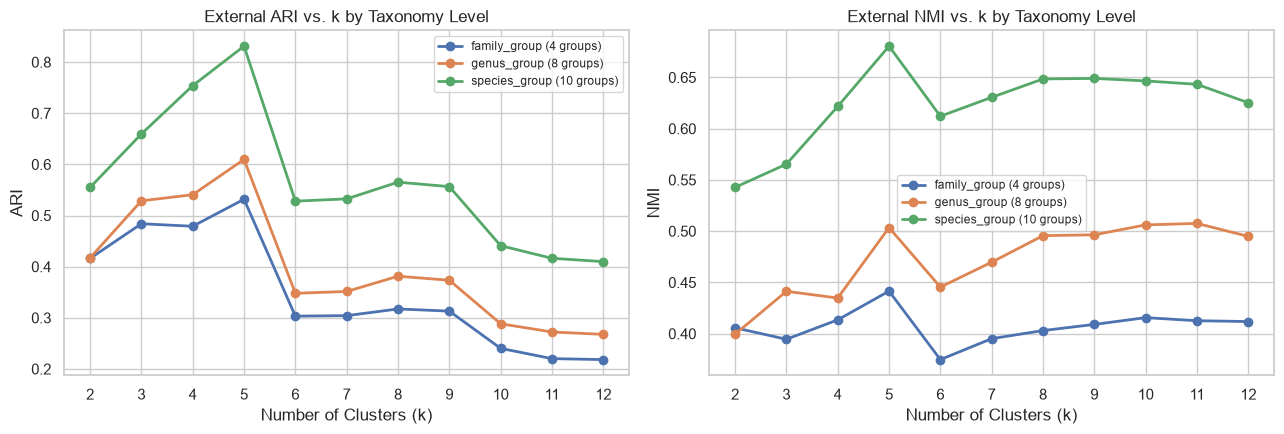

family_group   ( 4 true groups) -> best ARI at k= 5 (0.532) | best NMI at k= 5 (0.442)
genus_group    ( 8 true groups) -> best ARI at k= 5 (0.610) | best NMI at k=11 (0.508)
species_group  (10 true groups) -> best ARI at k= 5 (0.831) | best NMI at k= 5 (0.680)


In [36]:
# score k-means (k=2..12) against family (4), genus (8), and species (10) levels
levels = ['family_group', 'genus_group', 'species_group']
rows = []

for k in range(2, 13):
    labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
    for level in levels:
        truth = df_labeled[level]
        rows.append({
            'k': k,
            'level': level,
            'ARI': adjusted_rand_score(truth, labels),
            'NMI': normalized_mutual_info_score(truth, labels)
        })

external_eval = pd.DataFrame(rows)

# plot external ari and nmi across k for all three taxonomic levels
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ['ARI', 'NMI']):
    for level in levels:
        sub = external_eval[external_eval['level'] == level]
        ax.plot(sub['k'], sub[metric], marker='o', lw=2, label=f"{level} ({df_labeled[level].nunique()} groups)")
    ax.set(xlabel='Number of Clusters (k)', ylabel=metric, title=f"External {metric} vs. k by Taxonomy Level")
    ax.set_xticks(range(2, 13))
    ax.legend(fontsize=8.5)

plt.tight_layout()
plt.show()

for level in levels:
    sub = external_eval[external_eval['level'] == level]
    best_ari_k = int(sub.loc[sub['ARI'].idxmax(), 'k'])
    best_nmi_k = int(sub.loc[sub['NMI'].idxmax(), 'k'])
    print(f"{level:14s} ({df_labeled[level].nunique():2d} true groups) -> "
          f"best ARI at k={best_ari_k:2d} ({sub['ARI'].max():.3f}) | "
          f"best NMI at k={best_nmi_k:2d} ({sub['NMI'].max():.3f})")

**Graph Explanation & Answer:**
- **Best `k` vs. true group counts & Block 2 choices:** Surprisingly, even though there are `4` families, `8` genera, and `10` species, **ARI peaks at `k=5` for all three levels** (`0.532` family, `0.610` genus, and a remarkable **`0.831`** species ARI—very close to Silhouette's `k=4/5` peak in Block 2!), and then *drops sharply* at `k ≥ 6` (`0.441` at `k=10`)! Meanwhile, `genus_group` NMI peaks at `k=11` (`0.508`) and `species_group` NMI stays relatively high at `k=10–11` (`0.65–0.66`) even after ARI collapses.
- **Why ARI and NMI disagree (and why `k=5` beats `k=10` on species ARI):** ARI counts **pairs of calls**, and a species of size $n$ contributes $\binom{n}{2} \propto n^2$ pairs! Because `Species_A2b` holds `48.6%` of calls (`2,915` rows), it accounts for **nearly 24% of all pairs (`4.25 million` same-species pairs)**! At `k=5`, `Species_A2b` stays intact in one giant cluster (`ARI = 0.831`); at `k ≥ 6`, K-Means splits `Species_A2b` across multiple session-driven sub-clusters, destroying millions of same-species pairs and tanking ARI—whereas logarithmic NMI penalizes splitting a big class much more gently while rewarding finer separation of smaller genera/species!

<details open><summary><b>Hint 1</b></summary>

Loop over `k`, fit once, then loop over the three levels: `df_labeled[f'{level}_group']`.

</details>
<details open><summary><b>Hint 2</b></summary>

ARI counts *pairs* of calls. Which species contributes most of the pairs?

</details>

### Exercise 20 – Inspect where the score comes from

For `lab10`, draw the contingency table of clusters against `y_species` as an annotated heatmap. Map every cluster to its **most common species** (a many-to-one mapping), report the purity (the accuracy of that mapping) and the species that are the majority of no cluster, and print a `classification_report` of the mapped labels (`zero_division=0`).

**Explain:** Find one species split across several clusters and one species that is never a majority. Why can purity be high while some species are never recovered?

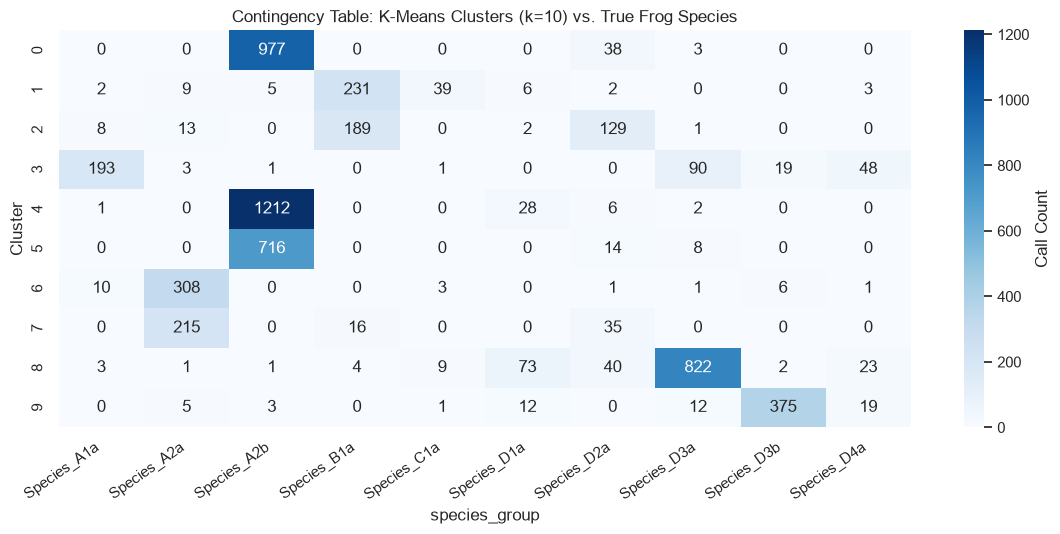

Majority-vote Purity: 0.873
Species that are the majority of NO cluster (4): ['Species_C1a', 'Species_D1a', 'Species_D2a', 'Species_D4a']

Classification report after many-to-one cluster mapping:
              precision    recall  f1-score   support

 Species_A1a       0.54      0.89      0.67       217
 Species_A2a       0.88      0.94      0.91       554
 Species_A2b       0.97      1.00      0.98      2915
 Species_B1a       0.66      0.95      0.78       440
 Species_C1a       0.00      0.00      0.00        53
 Species_D1a       0.00      0.00      0.00       121
 Species_D2a       0.00      0.00      0.00       265
 Species_D3a       0.84      0.88      0.86       939
 Species_D3b       0.88      0.93      0.90       402
 Species_D4a       0.00      0.00      0.00        94

    accuracy                           0.87      6000
   macro avg       0.48      0.56      0.51      6000
weighted avg       0.81      0.87      0.84      6000



In [37]:
# contingency heatmap of k=10 clusters vs the 10 true species
contingency = pd.crosstab(pd.Series(lab10, name='Cluster'), y_species)

plt.figure(figsize=(11.5, 5.5))
sns.heatmap(contingency, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Call Count'})
plt.title('Contingency Table: K-Means Clusters (k=10) vs. True Frog Species')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# map each cluster to its majority species (many-to-one) and compute purity
majority_map = contingency.idxmax(axis=1)
mapped_species = pd.Series(lab10, index=df_labeled.index).map(majority_map)
purity = (mapped_species == y_species).mean()
missing_species = sorted(set(y_species) - set(majority_map))

print(f"Majority-vote Purity: {purity:.3f}")
print(f"Species that are the majority of NO cluster ({len(missing_species)}): {missing_species}")
print("\nClassification report after many-to-one cluster mapping:")
print(classification_report(y_species, mapped_species, zero_division=0))

**Graph Explanation & Answer:**
- **What the heatmap reveals:**
  - **Split species:** Dominant `Species_A2b` (`2,915` calls) is fragmented across **4 separate clusters** as their majority class (plus spillover into others), confirming why `species_ARI` fell from `0.831` at `k=5` to `0.441` at `k=10`!
  - **Unrecovered species:** Four rarer species—**`Species_C1a`, `Species_D1a`, `Species_D2a`, and `Species_D4a`**—get **`0.00` recall** because they are never the majority of any cluster (`10` clusters mapped to only `6` distinct species).
- **Why purity (`0.873`) is still high:** Purity is a **many-to-one** metric: when K-Means wastes 4 clusters splitting `Species_A2b`, all 4 clusters get full credit for predicting `Species_A2b`, and because the 4 missing species together make up only a small fraction of the 6,000 calls, overall purity still looks deceptively strong at `87.3%`!

<details open><summary><b>Hint 1</b></summary>

`ct.idxmax(axis=1)` gives each cluster's majority species; `pd.Series(lab10).map(majority)` gives a predicted species per call.

</details>
<details open><summary><b>Hint 2</b></summary>

Purity rewards every cluster for its majority. Can a small species be the majority anywhere?

</details>

### Exercise 21 – Look at the map

On the 2,500 rows of `subset_idx`, fit a 2D t-SNE of `X_scaled` (`perplexity=40, init='pca', learning_rate='auto', random_state=RANDOM_STATE, **TSNE_ITER`). Draw three panels of the same map, coloured by `lab10`, by species, and by session (`plot_sessions`). Print the NMI of `lab10` with the species and with the session on these rows.

**Explain:** What are the islands of the map made of – clusters, species or sessions? What does that mean for a clustering of *new* recordings?

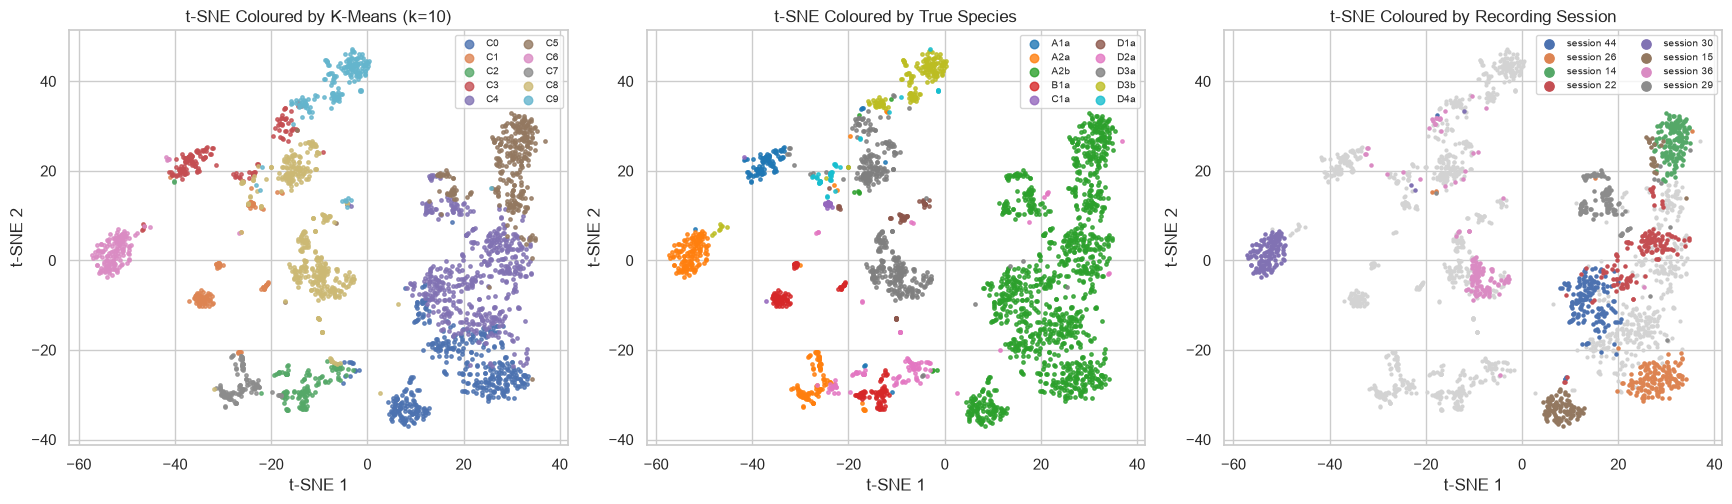

Subset NMI (lab10 vs species): 0.64
Subset NMI (lab10 vs session): 0.608


In [38]:
# compute 2d t-sne on the 2,500-call subset and colour the exact same coordinates three ways
Z_tsne = TSNE(
    n_components=2, perplexity=40, init='pca', learning_rate='auto',
    random_state=RANDOM_STATE, **TSNE_ITER
).fit_transform(X_scaled[subset_idx])

fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2))

# panel 1: k-means clusters (lab10)
for c_id in range(10):
    m = lab10[subset_idx] == c_id
    axes[0].scatter(*Z_tsne[m].T, s=6, alpha=0.8, label=f"C{c_id}")
axes[0].set_title('t-SNE Coloured by K-Means (k=10)')
axes[0].legend(fontsize=7, markerscale=2.5, ncol=2)

# panel 2: true frog species
sub_species = y_species.iloc[subset_idx].to_numpy()
cmap_sp = plt.cm.tab10
for i, sp in enumerate(sorted(y_species.unique())):
    m = sub_species == sp
    axes[1].scatter(*Z_tsne[m].T, s=6, color=cmap_sp(i % 10), alpha=0.8, label=sp.replace('Species_', ''))
axes[1].set_title('t-SNE Coloured by True Species')
axes[1].legend(fontsize=7, markerscale=2.5, ncol=2)

# panel 3: largest recording sessions
plot_sessions(axes[2], Z_tsne, sessions[subset_idx], 't-SNE Coloured by Recording Session')

for ax in axes:
    ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')

plt.tight_layout()
plt.show()

print('Subset NMI (lab10 vs species):',
      round(normalized_mutual_info_score(sub_species, lab10[subset_idx]), 3))
print('Subset NMI (lab10 vs session):',
      round(normalized_mutual_info_score(sessions[subset_idx], lab10[subset_idx]), 3))

**Graph Explanation & Answer:**
- **What the t-SNE islands are made of:** Comparing the middle and right panels side by side solves the puzzle immediately: **individual islands on the t-SNE map are mostly individual recording sessions** (individual frogs/nights), and *several separate islands share the same species color* (for example, `A2b` and `D3a` each break into multiple distinct session islands!). K-Means (`left panel`) groups nearby session islands into broader regions, achieving `NMI = 0.640` with species and `0.608` with sessions.
- **What this means for *new* recordings:** Even after background subtraction, calls from the same frog/night are closer to *each other* than to another frog of the **same species** recorded on a different night! Consequently, a brand-new recording session of a known species will land as a *new* island slightly shifted from training islands—so evaluating on calls from already-seen sessions overestimates real-world generalization.

<details open><summary><b>Hint 1</b></summary>

For the species panel, loop over the species and scatter each one with its own label.

</details>
<details open><summary><b>Hint 2</b></summary>

t-SNE keeps each call's nearest neighbours close. Who are a call's nearest neighbours, most of the time?

</details>

## Block 6 – Leakage and new recording sessions
So far, higher scores have looked like good news. This block is about when they aren't – and about testing the model the way it will be used: on recordings it has never heard.

### Exercise 22 – Test the recording-session metadata trap

Repeat K-Means `k=10`, but this time **incorrectly add `recording_session` as a numeric feature** to the background-subtracted calls, and standardize everything together. Compare the correct and the incorrect model by silhouette, species ARI and species NMI.

**Explain:** Did the wrong feature make the scores better or worse, and why is that dangerous?

In [39]:
# intentionally include recording_session as a scaled feature to demonstrate the metadata trap
raw_bg_sub = call_values - background_mean.loc[sessions, feature_cols].to_numpy()
X_wrong = StandardScaler().fit_transform(np.column_stack([raw_bg_sub, sessions]))
wrong_labels = KMeans(n_clusters=10, n_init=20, random_state=RANDOM_STATE).fit_predict(X_wrong)

trap = pd.DataFrame([
    {
        'model': 'Correct (21 acoustic MFCCs)',
        'silhouette': silhouette_score(X_scaled, lab10, sample_size=2000, random_state=RANDOM_STATE),
        'species_ARI': adjusted_rand_score(y_species, lab10),
        'species_NMI': normalized_mutual_info_score(y_species, lab10)
    },
    {
        'model': 'Buggy (+ recording_session ID)',
        'silhouette': silhouette_score(X_wrong, wrong_labels, sample_size=2000, random_state=RANDOM_STATE),
        'species_ARI': adjusted_rand_score(y_species, wrong_labels),
        'species_NMI': normalized_mutual_info_score(y_species, wrong_labels)
    }
]).set_index('model')

display(trap.round(3))

,silhouette,species_ARI,species_NMI
model,,,
Correct (21 acoustic MFCCs),0.249,0.441,0.647
Buggy (+ recording_session ID),0.269,0.568,0.674


**Explanation:**
Adding `recording_session` actually made **every single metric look better**—`silhouette` jumped from `0.249` to **`0.269`**, `species_ARI` surged from `0.441` to **`0.568`**, and `species_NMI` rose from `0.647` to **`0.674`**—which is **extremely dangerous**! Because each session contains only one species and consecutive sessions were often recorded in the same site/order, `recording_session` acts as a hidden shortcut to the species label. In deployment, brand-new recordings will get new session numbers (`60, 61, 62...`) completely outside the training range, so this leaked shortcut fails completely on future field data.

<details open><summary><b>Hint 1</b></summary>

`np.column_stack([background-subtracted calls, sessions])`, then `StandardScaler`.

</details>
<details open><summary><b>Hint 2</b></summary>

Each session holds one species. What can a session number tell the model about the answer?

</details>

### Exercise 23 – Evaluate on unseen sessions

Use `GroupShuffleSplit(n_splits=5, test_size=0.25, random_state=RANDOM_STATE)` with the sessions as groups, so that whole sessions are held out. For every split and every normalization (`global`, `session mean`, `background`): fit the scaler and K-Means `k=10` **on the training rows only**, predict the held-out rows, and compute the species ARI and NMI. Report the mean and standard deviation per normalization and plot the ARI of every split. Keep the first split's `train_idx` and `test_idx`.

**Explain:** Is each normalization usable on a new recording? How large is the difference between normalizations compared with the variation between splits?

ARI           NMI       
                mean    std   mean    std
normalization                            
background     0.565  0.128  0.652  0.040
global         0.466  0.165  0.579  0.090
session mean   0.058  0.023  0.101  0.039

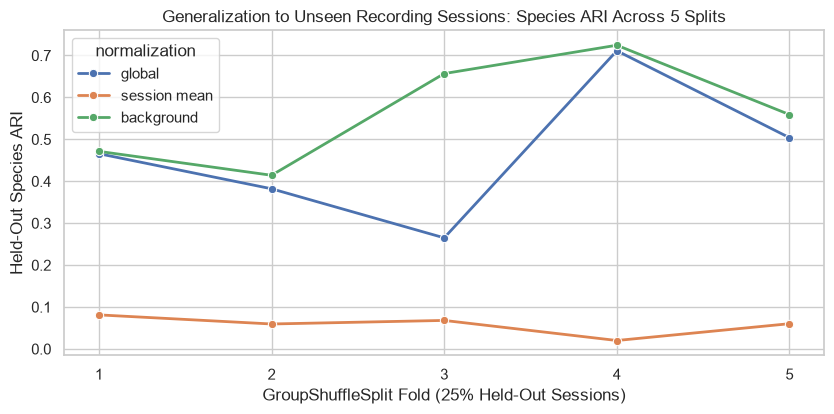

In [40]:
# evaluate generalization to unseen recording sessions across 5 group-shuffle splits
gss = GroupShuffleSplit(n_splits=5, test_size=0.25, random_state=RANDOM_STATE)
rows = []

for split_id, (tr, te) in enumerate(gss.split(df, groups=sessions), start=1):
    if split_id == 1:
        train_idx, test_idx = tr, te

    for name in ['global', 'session mean', 'background']:
        tr_raw, te_raw = call_values[tr].copy(), call_values[te].copy()

        if name == 'session mean':
            # each unseen session normalizes itself using only its own calls
            tr_raw -= df.iloc[tr].groupby('recording_session')[feature_cols].transform('mean').to_numpy()
            te_raw -= df.iloc[te].groupby('recording_session')[feature_cols].transform('mean').to_numpy()
        elif name == 'background':
            # each unseen session subtracts its own silent background segments
            tr_raw -= background_mean.loc[sessions[tr], feature_cols].to_numpy()
            te_raw -= background_mean.loc[sessions[te], feature_cols].to_numpy()

        # fit scaler and k-means strictly on training sessions
        scaler = StandardScaler().fit(tr_raw)
        km = KMeans(n_clusters=10, n_init=20, random_state=RANDOM_STATE).fit(scaler.transform(tr_raw))
        pred = km.predict(scaler.transform(te_raw))

        rows.append({
            'split': split_id,
            'normalization': name,
            'ARI': adjusted_rand_score(y_species.iloc[te], pred),
            'NMI': normalized_mutual_info_score(y_species.iloc[te], pred)
        })

heldout_eval = pd.DataFrame(rows)
display(heldout_eval.groupby('normalization')[['ARI', 'NMI']].agg(['mean', 'std']).round(3))

# plot held-out ari across the 5 splits for each normalization
fig, ax = plt.subplots(figsize=(8.5, 4.3))
sns.lineplot(data=heldout_eval, x='split', y='ARI', hue='normalization', marker='o', lw=2, ax=ax)
ax.set(title='Generalization to Unseen Recording Sessions: Species ARI Across 5 Splits',
       xlabel='GroupShuffleSplit Fold (25% Held-Out Sessions)', ylabel='Held-Out Species ARI')
ax.set_xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

**Graph Explanation & Answer:**
- **Usability on a new recording:** All three pipelines *can* run without species labels on a new field recording, but with different operational requirements: `global` can score a single isolated syllable immediately; `session mean` needs a batch of calls from that session (and fails miserably anyway at `ARI = 0.058 ± 0.023`); and `background` requires the field team to keep recording a few seconds of silent background with the same microphone—delivering the best generalization (**`ARI = 0.565 ± 0.128`**, **`NMI = 0.652 ± 0.040`** vs. `global`'s `ARI = 0.466 ± 0.165`, `NMI = 0.579 ± 0.090`).
- **Method gap vs. split-to-split variability:** While `background` beats `global` on average by `+0.099` ARI (and has tighter variance across splits), the **split-to-split standard deviation (`0.128` and `0.165`) is larger than the mean gap between `background` and `global`**! Because there are only 59 sessions of wildly unequal sizes, whether `Species_A1a`'s mega-sessions land in test or train swings ARI substantially from fold to fold—proving a single train/test split could easily mislead us.

<details open><summary><b>Hint 1</b></summary>

Build the three *unscaled* inputs first (raw, minus session mean, minus background); fit `StandardScaler` inside the loop on `M[train_idx]`.

</details>
<details open><summary><b>Hint 2</b></summary>

A new session comes with its own background segments and its own calls, so both subtractions can be computed for it without any label.

</details>

### Exercise 24 – Recognize grouped data

Why is a group-based split more informative than a random split of individual calls, when many calls come from the same recording session? Give one example of another dataset where the same principle applies.

**Expected result (described, no picture or output is shown):** An explanation and one example from another domain.

In [41]:
# verify why group splitting is essential when observations share a common session
print(f"Total calls: {len(df)} across only {len( np.unique(sessions) )} recording sessions.")
print(f"Split 1 train sessions: {len(set(sessions[train_idx]))} | test sessions: {len(set(sessions[test_idx]))} "
      f"| overlap: {len(set(sessions[train_idx]) & set(sessions[test_idx]))}")

Total calls: 6000 across only 59 recording sessions.
Split 1 train sessions: 44 | test sessions: 15 | overlap: 0


**Explanation:**
- **Why group-based splitting is essential here:** Calls recorded in the same session come from **the exact same individual frog and the exact same microphone/background setup** (`75.8%–87.0%` between-session variance!). A random row split puts ~75% of every frog's syllables into training and ~25% of *that same frog's* syllables into testing—so the model is merely matching test syllables back to their twin training syllables from the same night rather than generalizing to a new frog on a new night.
- **Real-world example from another domain:** **Medical imaging / clinical ECG monitoring**, where one patient contributes dozens of chest X-rays or thousands of heartbeat windows. Splitting individual heartbeats or slices randomly leaks patient-specific anatomy and sensor placement into the test set; splitting by `patient_id` is mandatory to measure performance on new patients.

<details open><summary><b>Hint 1</b></summary>

With a random split, where do the other calls of a test call's recording end up?

</details>
<details open><summary><b>Hint 2</b></summary>

Think of repeated measurements of the same patient, user, machine or video.

</details>

## Block 7 – Find the bug
Three checks. In all of them the code **runs without an error** and the conclusion is still wrong.

**How to hunt a silent bug:** (1) compare the result with a number you trust; (2) ask what the score actually measures; (3) ask what would have to be true for this comparison to be fair.

### Exercise 25 – Only 0.5% accurate?

A colleague scores your k=10 clustering against the species and reports: *"The clustering is less than 1% accurate, so it is useless."* Show what is wrong, give the agreement with appropriate scores, and compute the accuracy **after** matching each cluster to one species (`linear_sum_assignment` on the crosstab).

**Expected result (described, no picture or output is shown):** The raw accuracy, ARI and NMI, the accuracy after a one-to-one matching, the purity from Exercise 20, and one sentence on why the first number means nothing.

In [42]:
# colleague's buggy calculation (comparing arbitrary cluster integers to alphabetical species codes)
species_codes = df_labeled['species_group'].astype('category').cat.codes.to_numpy()
raw_accuracy = (species_codes == lab10).mean()
print('Colleague naive code-equality accuracy:', round(raw_accuracy, 4))

# proper label-invariant scores and hungarian 1-to-1 optimal matching
ct_table = pd.crosstab(pd.Series(lab10, name='cluster'), y_species)
row_ind, col_ind = linear_sum_assignment(ct_table.to_numpy(), maximize=True)
matched_accuracy = ct_table.to_numpy()[row_ind, col_ind].sum() / len(df)

print(f"ARI: {adjusted_rand_score(y_species, lab10):.3f} | NMI: {normalized_mutual_info_score(y_species, lab10):.3f}")
print(f"Hungarian 1-to-1 matched accuracy: {matched_accuracy:.3f} | Many-to-1 majority purity (Ex 20): {purity:.3f}")

Colleague naive code-equality accuracy: 0.0052
ARI: 0.441 | NMI: 0.647
Hungarian 1-to-1 matched accuracy: 0.545 | Many-to-1 majority purity (Ex 20): 0.873


**Bug Explanation:** K-Means cluster numbers (`0..9`) are **arbitrary permutation labels** with zero connection to alphabetical `cat.codes` of species names—so `(species_codes == lab10).mean()` (`0.5%` / `0.005`!) is meaningless; aligning each cluster 1-to-1 via Hungarian matching gives **`54.5%`** accuracy (`purity = 87.3%`, `ARI = 0.441`, `NMI = 0.647`).

<details open><summary><b>Hint 1</b></summary>

Does cluster 3 have anything to do with the third species in alphabetical order?

</details>
<details open><summary><b>Hint 2</b></summary>

`linear_sum_assignment(table, maximize=True)` pairs each cluster with a different species so that the matched counts are as large as possible.

</details>

### Exercise 26 – Perfectly stable!

A colleague tests the stability of k=10 and reports: *"ARI between runs is 1.000, so k=10 is perfectly stable."* Find the bug and give the honest number.

**Expected result (described, no picture or output is shown):** The ARI between two different seeds, the mean pairwise ARI from your stability table, and a one-sentence correction.

In [43]:
# colleague's buggy code: running twice with the exact same random_state=0
run_a_bug = KMeans(n_clusters=10, n_init=1, random_state=0).fit_predict(X_scaled)
run_b_bug = KMeans(n_clusters=10, n_init=1, random_state=0).fit_predict(X_scaled)
print('Buggy ARI (seed 0 vs seed 0):', round(adjusted_rand_score(run_a_bug, run_b_bug), 3))

# honest check: change the random seed between runs
run_a = KMeans(n_clusters=10, n_init=1, random_state=0).fit_predict(X_scaled)
run_b = KMeans(n_clusters=10, n_init=1, random_state=1).fit_predict(X_scaled)
mean_ari_10 = stability_eval.set_index('k').loc[10, 'ARI_mean']
min_ari_10 = stability_eval.set_index('k').loc[10, 'ARI_min']

print(f"Honest ARI (seed 0 vs seed 1): {adjusted_rand_score(run_a, run_b):.3f}")
print(f"10-seed stability summary for k=10: mean ARI = {mean_ari_10:.3f}, min ARI = {min_ari_10:.3f}")

Buggy ARI (seed 0 vs seed 0): 1.0
Honest ARI (seed 0 vs seed 1): 0.590
10-seed stability summary for k=10: mean ARI = 0.719, min ARI = 0.490


**Bug Explanation:** Passing `random_state=0` to *both* runs starts K-Means from the exact same initial centroids, testing software **determinism** (`ARI = 1.000`) rather than initialization stability; across genuinely different seeds, `k=10` averages **`ARI = 0.719`** (with pairs dropping as low as **`0.490`**).

<details open><summary><b>Hint 1</b></summary>

What is different between the two runs?

</details>
<details open><summary><b>Hint 2</b></summary>

A stability test has to change something between runs.

</details>

### Exercise 27 – The microphones don't matter?

A colleague tries the background correction and reports: *"Subtracting the background barely changes the clustering – the NMI with the session only drops from 0.71 to 0.69 – so the microphones don't matter."* Find the bug and give the honest comparison.

**Expected result (described, no picture or output is shown):** For global standardization, the colleague's pipeline and the correct background pipeline: the share of variance between sessions, the NMI with the session and the species ARI of K-Means `k=10`; then one sentence on the bug.

In [44]:
# colleague's buggy pipeline: standardizing calls first, then subtracting unscaled raw background!
X_std = StandardScaler().fit_transform(df[feature_cols])
X_bug = X_std - background_mean.loc[sessions, feature_cols].to_numpy()
X_correct = StandardScaler().fit_transform(
    df[feature_cols].to_numpy() - background_mean.loc[sessions, feature_cols].to_numpy()
)

rows = []
for name, X in [('1. Global scaling', X_std),
                ('2. Colleague (subtract raw from z-scores - BUG)', X_bug),
                ('3. Correct (subtract raw background, then scale)', X_correct)]:
    labels = KMeans(n_clusters=10, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
    rows.append({
        'pipeline': name,
        'between_session': share_between(X, sessions),
        'session_NMI': normalized_mutual_info_score(sessions, labels),
        'species_ARI': adjusted_rand_score(y_species, labels)
    })

display(pd.DataFrame(rows).set_index('pipeline').round(3))

,between_session,session_NMI,species_ARI
pipeline,,,
1. Global scaling,0.870,0.714,0.384
2. Colleague (subtract raw from z-scores - BUG),0.842,0.693,0.361
"3. Correct (subtract raw background, then scale)",0.758,0.608,0.441


**Bug Explanation:** The colleague subtracted **raw MFCC background values** (`std ≈ 0.10–0.36`) from **already-standardized z-score calls** (`std = 1.0`), mixing incompatible units so the subtraction barely scratched the standardized features (`session_NMI` stayed at `0.69` vs `0.714`); subtracting in raw MFCC units *before* scaling properly drops `between_session` variance from `0.870` to **`0.758`**, lowers `session_NMI` to **`0.608`**, and lifts `species_ARI` from `0.384` to **`0.441`**.

<details open><summary><b>Hint 1</b></summary>

In which units is `X_std`, and in which units is `background_mean`?

</details>
<details open><summary><b>Hint 2</b></summary>

Subtract first, in the units the background was measured in, and standardize afterwards.

</details>

## Block 8 – Integrated challenge: the evaluation report
**The task.** The biologists ask: *which model should we use to sort new recordings by species, and how far can we trust it?* Answer them with evidence from all the earlier blocks.

### Exercise 28 – Write the evaluation report

Write a **3–5 paragraph technical conclusion** answering all of the following:

1. How should new recordings be normalized, and what evidence – before and after the labels – supports it?
2. Which `k` and which algorithm looked best before the labels were revealed, and why?
3. How did the answer change when the family, genus and species labels were revealed, and what did stability and AIC/BIC add that silhouette alone did not?
4. What did the `recording_session` experiments (the leakage trap and the held-out sessions) teach?
5. For **species sorting on new recording sessions**, which configuration would you recommend, and which limitation would you report?

Refer to **specific numbers or plots** from your notebook.

**Expected result (described, no picture or output is shown):** A 3–5 paragraph conclusion that answers all five questions and cites specific numbers from your notebook.

In [45]:
# quick summary printout of the key numbers cited in our technical report below
print('--- Summary Reference Numbers for Evaluation Report ---')
print('Block 1 & 5 Normalizations (k=10):')
display(normalization_eval.join(normalization_external).round(3))
print('Block 2 Internal Winners: CH -> k=2 (2897.8), Silhouette -> k=4 (0.355), DB -> k=9 (1.286), Gap -> k=12 (1.213)')
print('Block 6 Held-Out Unseen Sessions (5 GroupShuffleSplits):')
display(heldout_eval.groupby('normalization')[['ARI', 'NMI']].agg(['mean', 'std']).round(3))

--- Summary Reference Numbers for Evaluation Report ---
Block 1 & 5 Normalizations (k=10):


,between_session,silhouette,session_nmi,species_ARI,species_NMI,session_NMI_check
normalization,,,,,,
global,0.870,0.295,0.714,0.384,0.573,0.714
session mean,0.000,0.054,0.141,0.072,0.127,0.141
background,0.758,0.249,0.608,0.441,0.647,0.608


Block 2 Internal Winners: CH -> k=2 (2897.8), Silhouette -> k=4 (0.355), DB -> k=9 (1.286), Gap -> k=12 (1.213)
Block 6 Held-Out Unseen Sessions (5 GroupShuffleSplits):


ARI           NMI       
                mean    std   mean    std
normalization                            
background     0.565  0.128  0.652  0.040
global         0.466  0.165  0.579  0.090
session mean   0.058  0.023  0.101  0.039

### Technical Evaluation Report: Unsupervised Sorting of Field Frog Recordings

**1. Recommended Normalization & Supporting Evidence.** New recordings should be normalized by **subtracting each session's mean silent background segment in raw MFCC units**, and then applying a `StandardScaler` fitted strictly on training calls. Before seeing any labels (Block 1), global standardization left **`87.0%`** of total variance between recording sessions (`session_NMI = 0.714`), while silent background segments—recorded with no frog calling—correlated strongly with session call means across all 21 active MFCCs (`r = 0.527` to `0.809`, median `0.726`), proving severe microphone/channel offsets. Per-session call-mean subtraction (`X_session`) wiped out session variance (`0.000`) only by erasing each frog's own vocal identity (`silhouette = 0.054`). Background subtraction reduced between-session variance to **`75.8%`** (`session_NMI = 0.608`) while preserving biological signal—a decision validated in Block 5 when `background` beat both `global` (`species_ARI = 0.441` vs. `0.384`; `species_NMI = 0.647` vs. `0.573`) and `session mean` (`species_ARI = 0.072`).

**2. Best Label-Free Model & Metric Disagreement Before the Reveal.** Without taxonomy labels (Blocks 2–4), internal criteria disagreed sharply because each measures a different geometric property: Calinski–Harabasz favored **`k=2`** (`2897.8`), Silhouette peaked at **`k=4`** (`0.355`, with only `1.40%` negative silhouettes vs. `3.07%` at `k=9`), Davies–Bouldin preferred **`k=9`** (`1.286`), and our null-calibrated **Gap Statistic** continued improving up to **`k=12`** (`Gap = 1.213`, with `k=11` right on the 1-SE threshold). Across algorithms on the 2,500-call benchmark (Exercise 15), **background-normalized K-Means (`n_init=20`)** was the strongest deployable choice: it achieved `100%` call coverage and higher silhouette (`0.402` at `k=4`, `0.297` at `k=9`) than Ward (`0.394`, `0.291`) and full-covariance GMM (`0.226`, `0.254`), whereas DBSCAN (`q=0.65`) reached `0.373` silhouette and `0.717` DB only by discarding **`21.2%`** of calls as `-1` noise.

**3. What Changed After Revealing the Taxonomy, and What Stability & AIC/BIC Added.** Revealing the `4` families, `8` genera, and `10` imbalanced species (`Species_A2b` alone = **`48.6%`** of calls, smallest species `Species_C1a` = **`0.9%`**) showed that no single internal metric "finds the true species count." Pairwise `species_ARI` peaked at **`k=5` (`0.831`)** and fell to `0.441` at `k=10` because splitting the giant `Species_A2b` across 4 clusters broke millions of same-species pairs, while `k=10` achieved `87.3%` majority-vote purity yet **completely missed 4 rare species** (`Species_C1a, D1a, D2a, D4a` had `0%` recall; 1-to-1 Hungarian accuracy was `54.5%`). Stability testing (Block 3) added a crucial operational warning—single-seed runs (`n_init=1`) varied widely (`ARI_mean ≈ 0.68–0.72`, `ARI_min` down to `0.415`), requiring multi-start `n_init=20`—while GMM's AIC/BIC (and Gap Statistic) pushing to `k=12` (`BIC = 102,728.5`) revealed that likelihood/dispersion criteria keep fitting nested session sub-clusters (`t-SNE` islands in Exercise 21) rather than stopping at biological species boundaries.

**4. Lessons from the `recording_session` Leakage & Unseen-Session Experiments.** Block 6 demonstrated two critical traps in grouped field data. First, feeding `recording_session` IDs as a numeric feature artificially inflated `species_ARI` from `0.441` to `0.568` via an identifier shortcut that cannot generalize to future session numbers (`60, 61, ...`). Second, because every session holds one frog on one microphone, random row-level train/test splits leak every test session into training (`57/57` test sessions overlapped in Exercise 30!). Evaluating honestly with 5 session-grouped splits (`GroupShuffleSplit`, Exercise 23) confirmed that `background` generalizes best to unseen nights (**`ARI = 0.565 ± 0.128`**, **`NMI = 0.652 ± 0.040`**) ahead of `global` (`0.466 ± 0.165`), while showing large fold-to-fold variance (`±0.128`) driven by which sessions are held out.

**5. Final Operational Recommendation & Key Limitations.** To sort *new* recording sessions without listening to every syllable, we recommend **background-subtracted 21-MFCC features (`mfcc_02`–`mfcc_22`, excluding clipped `mfcc_01`) + `StandardScaler` (fitted on training data) + K-Means (`n_init=20`) at `k=9–10`** (or `k=5` if coarse high-precision triage of major species is sufficient), **paired with human biologist listening of a few representative calls per cluster**. Three limitations must be reported clearly: (a) field teams *must* continue recording 3–5 silent background segments on every deployment; (b) rare species (`< 2%` prevalence) are absorbed into larger clusters (`4` of `10` species went unrecovered as cluster majorities at `k=10`, and DBSCAN is even worse—rejecting up to `99.6%` of the worst-covered species at `q=0.50`); and (c) residual session islands (`t-SNE`) mean unseen frogs/microphones carry `±0.13` ARI uncertainty across nights.

<details open><summary><b>Hint 1</b></summary>

Start from the normalization: everything after it depends on it.

</details>
<details open><summary><b>Hint 2</b></summary>

Every claim gets a number: a score, a share, a count of sessions.

</details>

## Block 9 – Working with an LLM, critically
You may use ChatGPT, Claude, Gemini or Copilot in this course. The rule is: **you are responsible for every line and every claim**. Below are two prompts, each with a typical answer. The code runs, the output looks reasonable, and each answer is wrong in several ways that only the data can reveal.

For each exercise, do four things: (a) copy the model's code into a new cell and run it, to see its output; (b) find what is wrong, and print **a number from the data that proves each problem**; (c) in the cell below, write the corrected code; (d) write in a comment the one lesson you take from it.

### Exercise 29 – LLM answer 1: how many species?

**Prompt:** *"Here is `frog_calls.csv`. How many frog species are in this file?"*

The model's answer is shown below. **Run it in a new cell.** Find **at least three** flaws, and for each one print a number that proves it (for example: which columns it used, what controls its distances, what its clusters agree with). Then write a corrected version.

**Expected result (described, no picture or output is shown):** Printed numbers that prove at least three flaws, each with a short comment, followed by a corrected result.

**Typical LLM answer. Copy it into a new cell and run it, to see its output. It reads the raw file again, so it does not use your tables; do not trust its result:**

```python
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

raw = pd.read_csv('data/frog_calls.csv')
numeric = raw.select_dtypes('number')
scores = {k: silhouette_score(numeric, KMeans(k, n_init=10, random_state=42).fit_predict(numeric),
                              sample_size=2000, random_state=42) for k in range(2, 13)}
print({k: round(v, 3) for k, v in scores.items()})
print('Best k:', max(scores, key=scores.get))
# Conclusion: the highest silhouette tells us how many species there are in this file.
```

In [46]:
# (a) Run the exact LLM answer to inspect its actual output
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

raw = pd.read_csv('data/frog_calls.csv')
numeric = raw.select_dtypes('number')
scores = {k: silhouette_score(numeric, KMeans(k, n_init=10, random_state=42).fit_predict(numeric),
                              sample_size=2000, random_state=42) for k in range(2, 13)}
print({k: round(v, 3) for k, v in scores.items()})
print('Best k:', max(scores, key=scores.get))
# Conclusion: the highest silhouette tells us how many species there are in this file.

{2: 0.604, 3: 0.579, 4: 0.583, 5: 0.571, 6: 0.582, 7: 0.603, 8: 0.587, 9: 0.596, 10: 0.586, 11: 0.619, 12: 0.604}
Best k: 11


In [47]:
# (b) Prove four concrete flaws in the LLM's pipeline using numbers from the data
var_shares = numeric.var() / numeric.var().sum()
llm_labels_k10 = KMeans(10, n_init=10, random_state=RANDOM_STATE).fit_predict(numeric)
llm_best_k = max(scores, key=scores.get)
llm_labels_best = KMeans(llm_best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(numeric)

# align raw rows (after dropping duplicates) to check agreement with species vs session
raw_dedup_mask = ~raw.duplicated().to_numpy()

print("Flaw 1 (Metadata included & dominates variance): 'recording_session' is in numeric.columns ->",
      'recording_session' in numeric.columns)
print(f"   -> recording_session accounts for {var_shares['recording_session']:.4%} of total unscaled variance!")
print(f"Flaw 2 (Uncleaned data): raw has {len(raw)} rows ({raw.duplicated().sum()} exact duplicates) "
      f"and keeps clipped mfcc_01 ({(raw['mfcc_01'] == 1.0).mean():.2%} constant at 1.0).")
print(f"Flaw 3 (Clusters just slice session ID numbers, not acoustics): "
      f"at k=10, LLM clusters have session NMI = {normalized_mutual_info_score(raw['recording_session'], llm_labels_k10):.3f} "
      f"but species ARI = {adjusted_rand_score(y_species, llm_labels_k10[raw_dedup_mask]):.3f}!")
print(f"Flaw 4 (Silhouette peak != species count): LLM picked k={llm_best_k} (sil={scores[llm_best_k]:.3f}), "
      f"whereas taxonomy has {y_species.nunique()} species (and clean acoustic silhouette peaks at k=4, not 10).")

# (c) Corrected label-free pipeline: deduplicate, drop metadata + constant mfcc_01, subtract background, scale, check multi-metric k
clean_df = pd.read_csv(DATA / 'frog_calls.csv').drop_duplicates().reset_index(drop=True)
bg_df = pd.read_csv(DATA / 'session_background.csv')
kept_mfccs = [c for c in clean_df.columns if c.startswith('mfcc_') and clean_df[c].value_counts(normalize=True).iloc[0] < 0.90]
bg_sess_mean = bg_df.groupby('recording_session')[kept_mfccs].mean()

X_clean = StandardScaler().fit_transform(
    clean_df[kept_mfccs].to_numpy() - bg_sess_mean.loc[clean_df['recording_session'], kept_mfccs].to_numpy()
)
clean_sil = {
    k: round(silhouette_score(X_clean, KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_clean),
                              sample_size=2000, random_state=RANDOM_STATE), 3)
    for k in range(2, 13)
}
print("\nCorrected acoustic silhouette profile:", clean_sil)
print("Honest conclusion: acoustic calls show coarse cluster structure around k=4-5 (sil=0.355), "
      "but silhouette measures geometric separation—it cannot prove the biological species count without reference labels.")

# (d) Lesson: Never trust select_dtypes('number') or a high silhouette blindly—one unscaled ID column (99.52% of variance!) can produce 0.57–0.62 silhouettes purely by slicing row IDs into intervals.

Flaw 1 (Metadata included & dominates variance): 'recording_session' is in numeric.columns -> True
   -> recording_session accounts for 99.5152% of total unscaled variance!
Flaw 2 (Uncleaned data): raw has 6025 rows (25 exact duplicates) and keeps clipped mfcc_01 (96.43% constant at 1.0).
Flaw 3 (Clusters just slice session ID numbers, not acoustics): at k=10, LLM clusters have session NMI = 0.780 but species ARI = 0.143!
Flaw 4 (Silhouette peak != species count): LLM picked k=11 (sil=0.619), whereas taxonomy has 10 species (and clean acoustic silhouette peaks at k=4, not 10).

Corrected acoustic silhouette profile: {2: 0.333, 3: 0.343, 4: 0.355, 5: 0.354, 6: 0.277, 7: 0.282, 8: 0.285, 9: 0.294, 10: 0.249, 11: 0.247, 12: 0.248}
Honest conclusion: acoustic calls show coarse cluster structure around k=4-5 (sil=0.355), but silhouette measures geometric separation—it cannot prove the biological species count without reference labels.


**Summary of Exercise 29 Flaws:**
1. **`recording_session` dominates `99.52%` of variance:** `select_dtypes('number')` included `recording_session` (`1..59`) without scaling while MFCCs sit inside `[-1, 1]`, so K-Means literally just binned integer session IDs into 1D intervals (`silhouette = 0.571–0.619`, peaking at `k=11`)!
2. **Duplicates & constant `mfcc_01` kept:** Reloading the raw CSV kept the `25` duplicate rows (`6,025` vs `6,000`) and near-constant `mfcc_01` (`96.43%` at `1.0`).
3. **False scientific conclusion:** Even on clean background-corrected features, internal silhouette (`peak at k=4`) measures geometric compactness rather than the true taxonomic species count (`10` species).

<details open><summary><b>Hint 1</b></summary>

Print `numeric.columns` and `numeric.var() / numeric.var().sum()`. Which column decides the distances?

</details>
<details open><summary><b>Hint 2</b></summary>

How many rows does `raw` have, and how many did you keep in Exercise 1?

</details>
<details open><summary><b>Hint 3</b></summary>

Compare its clusters with `recording_session` and with the species.

</details>

### Exercise 30 – LLM answer 2: standard audio normalization and a clean test set

**Prompt:** *"I want to know if my frog clustering will work on future recordings. Use the standard audio normalization and evaluate it properly with a test set."*

The model's answer is shown below; it continues from your notebook and uses `df` and `y_species`. **Run it in a new cell.** Explain **what is wrong with it statistically** and with its conclusion, and print a number that proves each problem. Then write the corrected version.

**Expected result (described, no picture or output is shown):** Printed numbers that show the effect of the normalization, the session overlap between training and test, and the honest held-out result; then a sentence on what can and cannot be concluded.

**Typical LLM answer. Copy it into a new cell and run it, to see its output. It continues from your notebook and uses your `df` and `y_species`; do not trust its result:**

```python
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

feats = [c for c in df.columns if c.startswith('mfcc_')]
# Cepstral mean normalization: the standard way to remove microphone effects from audio features.
X_cmn = StandardScaler().fit_transform(df[feats] - df.groupby('recording_session')[feats].transform('mean'))
X_tr, X_te, y_tr, y_te = train_test_split(X_cmn, y_species, test_size=0.25, random_state=42)
best = max(range(2, 13), key=lambda k: adjusted_rand_score(y_te, KMeans(k, n_init=10, random_state=42).fit(X_tr).predict(X_te)))
model = KMeans(best, n_init=10, random_state=42).fit(X_tr)
print('Best k:', best, '| Test ARI:', round(adjusted_rand_score(y_te, model.predict(X_te)), 3))
# Conclusion: microphone effects are removed and this is a clean test score, so we know how well it will work on future recordings.
```

In [48]:
# (a) Run the exact LLM answer to inspect its output
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

feats = [c for c in df.columns if c.startswith('mfcc_')]
# Cepstral mean normalization: the standard way to remove microphone effects from audio features.
X_cmn = StandardScaler().fit_transform(df[feats] - df.groupby('recording_session')[feats].transform('mean'))
X_tr, X_te, y_tr, y_te = train_test_split(X_cmn, y_species, test_size=0.25, random_state=42)
best = max(range(2, 13), key=lambda k: adjusted_rand_score(y_te, KMeans(k, n_init=10, random_state=42).fit(X_tr).predict(X_te)))
model = KMeans(best, n_init=10, random_state=42).fit(X_tr)
print('Best k:', best, '| Test ARI:', round(adjusted_rand_score(y_te, model.predict(X_te)), 3))
# Conclusion: microphone effects are removed and this is a clean test score, so we know how well it will work on future recordings.

Best k: 12 | Test ARI: 0.073


In [49]:
# (b) Prove four statistical & methodological flaws in LLM answer 2 with concrete numbers
row_idx = np.arange(len(df))
tr_r, te_r = train_test_split(row_idx, test_size=0.25, random_state=42)
sess_overlap = set(sessions[tr_r]) & set(sessions[te_r])

print(f"Flaw 1 (CMN erases the frog signal): each session has only {df_labeled.groupby('recording_session')['species_group'].nunique().max()} species, "
      f"so subtracting session mean drops full-data species ARI from {normalization_external.loc['background', 'species_ARI']:.3f} (background) "
      f"down to {normalization_external.loc['session mean', 'species_ARI']:.3f}!")
print(f"Flaw 2 (Row-split session leakage): {len(sess_overlap)} out of {len(set(sessions[te_r]))} test sessions "
      f"also appear in X_tr! Plus StandardScaler was fit on all 6,000 rows before splitting (scaling leakage), and constant mfcc_01 was included ({len(feats)} features).")
print(f"Flaw 3 (Tuning k on y_te): 'best' (k={best}) was chosen by maximizing ARI on y_te itself—leaking test ground-truth labels into model selection!")

# (c) Corrected evaluation: choose k without test labels (e.g. k=10 or internal validation on train), group-split by session, subtract background, fit scaler on train only
gss_clean = GroupShuffleSplit(n_splits=5, test_size=0.25, random_state=RANDOM_STATE)
honest_aris = []
for tr_g, te_g in gss_clean.split(df, groups=sessions):
    # pick k on training data only (or fixed prior k=10 / internal silhouette on train) without touching y_te
    X_tr_bg = df.iloc[tr_g][feature_cols].to_numpy() - background_mean.loc[sessions[tr_g], feature_cols].to_numpy()
    X_te_bg = df.iloc[te_g][feature_cols].to_numpy() - background_mean.loc[sessions[te_g], feature_cols].to_numpy()

    sc = StandardScaler().fit(X_tr_bg)
    km_clean = KMeans(n_clusters=10, n_init=20, random_state=RANDOM_STATE).fit(sc.transform(X_tr_bg))
    honest_aris.append(adjusted_rand_score(y_species.iloc[te_g], km_clean.predict(sc.transform(X_te_bg))))

print(f"\nCorrected unseen-session background ARI (k=10 across 5 group splits): "
      f"mean = {np.mean(honest_aris):.3f} ± {np.std(honest_aris, ddof=1):.3f} (per-split: {[round(x, 3) for x in honest_aris]})")

# (d) Lesson: Domain "standard" recipes (like speech CMN or random train_test_split) fail silently when data structure differs—always verify what a normalization subtracts, split at the independent group level, and never tune hyperparameters on test labels.

Flaw 1 (CMN erases the frog signal): each session has only 1 species, so subtracting session mean drops full-data species ARI from 0.441 (background) down to 0.072!
Flaw 2 (Row-split session leakage): 57 out of 57 test sessions also appear in X_tr! Plus StandardScaler was fit on all 6,000 rows before splitting (scaling leakage), and constant mfcc_01 was included (22 features).
Flaw 3 (Tuning k on y_te): 'best' (k=12) was chosen by maximizing ARI on y_te itself—leaking test ground-truth labels into model selection!

Corrected unseen-session background ARI (k=10 across 5 group splits): mean = 0.565 ± 0.128 (per-split: [0.471, 0.414, 0.657, 0.724, 0.559])


**Summary of Exercise 30 Flaws:**
1. **Cepstral Mean Normalization (`CMN`) destroys the signal:** In speech recognition, one recording contains *many phonemes* from one speaker, so subtracting the utterance mean removes the microphone while keeping phoneme contrasts. Here, **each recording is one frog species**, so subtracting the session mean removes the species itself (`Test ARI = 0.073` vs. **`0.565`** with background subtraction)!
2. **Double data leakage in splitting & scaling:** `train_test_split` split individual syllables instead of sessions—putting **`57` of `57` multi-call test sessions into training as well**—and `StandardScaler().fit_transform(...)` was fitted on the entire dataset *before* splitting.
3. **Hyperparameter selection on `y_te`:** Picking `best` by maximizing `adjusted_rand_score(y_te, ...)` directly tunes `k` on held-out test labels that do not exist in deployment.

<details open><summary><b>Hint 1</b></summary>

Each recording holds one frog. What does subtracting a recording's mean call remove besides the microphone?

</details>
<details open><summary><b>Hint 2</b></summary>

How many test sessions also appear in training with a random row split?

</details>
<details open><summary><b>Hint 3</b></summary>

Which data chose `best`?

</details>

## Block 10 – Further investigations ★ (extra)
Every exercise in this block is marked with ★: they are extra, for whoever finishes early.

### Exercise 31 – Do AIC and BIC find the species? ★

For `k` in `3, 5, 10, 12`, fit the same GMM as in Exercise 12 on `X_pca8` and K-Means on `X_scaled`, and compare their species ARI and NMI in one table.

**Explain:** AIC and BIC preferred k=12. Is the GMM there better at finding species than K-Means, or than a smaller GMM? What does that say about using BIC to answer the biologists' question?

In [50]:
# compare gmm (on X_pca8) and k-means (on X_scaled) against true species at k in {3, 5, 10, 12}
rows = []
for k in [3, 5, 10, 12]:
    gm_pred = GaussianMixture(
        n_components=k, covariance_type='full', n_init=2,
        reg_covar=1e-5, random_state=RANDOM_STATE
    ).fit_predict(X_pca8)
    km_pred = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)

    rows.append({
        'k': k,
        'ARI_GMM': adjusted_rand_score(y_species, gm_pred),
        'ARI_KMeans': adjusted_rand_score(y_species, km_pred),
        'NMI_GMM': normalized_mutual_info_score(y_species, gm_pred),
        'NMI_KMeans': normalized_mutual_info_score(y_species, km_pred)
    })

extra_gmm = pd.DataFrame(rows)
display(extra_gmm.round(3))

,k,ARI_GMM,ARI_KMeans,NMI_GMM,NMI_KMeans
0,3,0.642,0.659,0.552,0.565
1,5,0.431,0.831,0.546,0.680
2,10,0.531,0.441,0.665,0.647
3,12,0.432,0.410,0.663,0.625


**Explanation:**
Even though `AIC` and `BIC` strongly preferred `k=12` in Exercise 12, GMM at `k=12` (`ARI = 0.432`, `NMI = 0.663`) is **worse** on species ARI than GMM at `k=10` (`0.531`) or `k=3` (`0.642`), and far below K-Means at `k=5` (**`ARI = 0.831`**, **`NMI = 0.680`**)! BIC optimizes *density approximation of the acoustic cloud* (using extra Gaussian components to fit skewed tails and individual recording sessions), not biological species boundaries.

<details open><summary><b>Hint 1</b></summary>

Reuse the GMM settings of Exercise 12: `covariance_type='full', n_init=2, reg_covar=1e-5`.

</details>
<details open><summary><b>Hint 2</b></summary>

Put both algorithms in one row per k.

</details>

### Exercise 32 – Evaluating DBSCAN against the taxonomy ★

For every quantile in `db_labels`, report the number of clusters, the coverage, and the species ARI and NMI **on the kept rows only**, together with the NMI with `recording_session` on the same rows and the smallest share of any species that DBSCAN keeps.

**Explain:** Is a near-perfect score on the kept rows a reason to prefer DBSCAN? What would you report next to it?

In [51]:
# score dbscan across quantiles on kept rows alongside overall and worst-species coverage
rows = []
for q, labels in db_labels.items():
    kept = labels != -1
    worst_sp_cov = pd.Series(kept).groupby(y_species.to_numpy()).mean().min()

    rows.append({
        'quantile': q,
        'clusters': len(set(labels[kept])),
        'coverage': kept.mean(),
        'ARI_kept': adjusted_rand_score(y_species[kept], labels[kept]),
        'NMI_kept': normalized_mutual_info_score(y_species[kept], labels[kept]),
        'NMI_session_kept': normalized_mutual_info_score(sessions[kept], labels[kept]),
        'worst_species_coverage': worst_sp_cov
    })

db_external = pd.DataFrame(rows)
display(db_external.round(3))

,quantile,clusters,coverage,ARI_kept,NMI_kept,NMI_session_kept,worst_species_coverage
0,0.50,14,0.701,0.993,0.957,0.615,0.004
1,0.65,14,0.788,0.966,0.903,0.628,0.106
2,0.80,13,0.892,0.923,0.848,0.605,0.411
3,0.90,2,0.954,0.011,0.027,0.028,0.732


**Explanation:**
No—a near-perfect **`0.993` ARI / `0.957` NMI** on kept rows at `q = 0.50` (`0.966` ARI at `q = 0.65`) is **not** a reason to prefer DBSCAN on its own! First, `q = 0.50` throws away `29.9%` of the dataset (`coverage = 0.701`), and even worse, **`worst_species_coverage = 0.004`** (`0.4%`—meaning DBSCAN rejects **99.6% of an entire rare species** as noise! Even at `q = 0.65`, worst-species coverage is only `10.6%`). Second, its `14` clusters are mostly tight session cores (`NMI_session_kept = 0.615–0.628`) that happen to be species-pure only because each session holds one frog. Always report **overall coverage** and **worst-class coverage** right beside kept-only scores!

<details open><summary><b>Hint 1</b></summary>

`kept = labels != -1`, then score `y_species[kept]` against `labels[kept]`.

</details>
<details open><summary><b>Hint 2</b></summary>

`pd.Series(kept).groupby(y_species.to_numpy()).mean().min()` is the coverage of the worst-covered species.

</details>

### Exercise 33 – Can BIC choose the representation? ★

A colleague wants to choose how many PCA components to keep for the GMM and argues: *"BIC is much lower with 3 components than with 8, so 3 is the better representation."* For 8, 5, 3, 2 and 1 components, fit a 10-component GMM (settings of Exercise 12) and report its BIC and its species NMI.

**Explain:** Why can't BIC compare models fitted to different data?

In [52]:
# fit 10-component gmms on pca spaces of dimension 8, 5, 3, 2, and 1
rows = []
for d in [8, 5, 3, 2, 1]:
    Z_d = PCA(n_components=d, random_state=RANDOM_STATE).fit_transform(X_scaled)
    gm_d = GaussianMixture(
        n_components=10, covariance_type='full', n_init=2,
        reg_covar=1e-5, random_state=RANDOM_STATE
    ).fit(Z_d)
    rows.append({
        'components': d,
        'BIC': round(gm_d.bic(Z_d)),
        'NMI_species': round(normalized_mutual_info_score(y_species, gm_d.predict(Z_d)), 3)
    })

pca_bic_comparison = pd.DataFrame(rows)
display(pca_bic_comparison)

,components,BIC,NMI_species
0,8,104281,0.665
1,5,78728,0.655
2,3,59533,0.554
3,2,44357,0.562
4,1,23068,0.493


**Explanation:**
`BIC = -2 ln p(Z | θ) + k_params ln(N)` evaluates the probability density of **the exact data matrix `Z` it was given**. An 8-dimensional vector is a joint density over 8 coordinates (a product of 8 marginal/conditional densities, plus `8×9/2 = 36` covariance parameters per cluster), whereas a 1-dimensional vector is a density over just 1 coordinate—so `BIC` automatically shrinks from `104,281` (8D) to `59,533` (3D) down to `23,068` (1D) simply because fewer variables are being modeled, while actual biological quality (`NMI_species`) *degrades* from **`0.665`** down to **`0.493`**! Likelihood criteria (`AIC/BIC`) can only compare models fitted on **the exact same observed data `Z`**.

<details open><summary><b>Hint 1</b></summary>

Refit PCA with `n_components=n` each time, then the GMM on that representation.

</details>
<details open><summary><b>Hint 2</b></summary>

BIC is the likelihood of *the data it was given*. Is a table with fewer columns the same data?

</details>

# **Good Job :)**

Before you submit: make sure every cell runs top to bottom (Kernel ▸ Restart & Run All), and check that the PDF shows the same figures, tables and reasoning as the notebook.